# 1. Saúde da Mulher na África Subsaariana

Contracepção, pré-natal, assistência materno-infantil e desigualdades sociais: Quanto das diferenças rurais e urbanas se relacionam à riqueza e à escolaridade?

# 2. Equipe

Henrique Lima Gusmão (2025014508); 
Felipe Pires Franco ();
Izabella Galdino Correia ();
Alice Lina Oliveira da Silva ().".

# 3. Descrição dos dados

### 3.1 Obtenção dos dados

1. Acessamos o [DHS Program](https://dhsprogram.com/data/Access-Instructions.cfm), solicitamos acesso institucional e baixamos os microdados oficiais em arquivos ZIP contendo bases Stata (`.dta`).
2. Extraímos os arquivos Stata (`.dta`) e selecionamos os seis recodes que integram o modelo conceitual aprovado: entrevistas femininas (`IR`), histórico de nascimentos (`BR`), domicílios (`HR`), moradores (`PR`), crianças menores de 5 anos (`KR`) e entrevistas masculinas/parceiros (`MR`). Inquéritos fora do escopo relacional (como casais `CR`, antropometria legada `HW`, postos de saúde `SQ` e índices avulsos `WI`) foram descartados.
3. Executamos os scripts de preparação e filtragem (`preparar_dados_projeto.py` e `carregar_sqlite.py`), selecionamos as variáveis relevantes e convertemos os arquivos em **CSV compactado (`.csv.gz`)** na pasta `dados/relevantes/`, utilizados para popular o banco SQLite principal (`saude_mulher_dhs.db`) e o banco relacional normalizado em 3FN (`saude_mulher_normalizado.db`).
4. Utilizamos a aplicação **Python/Flask** do projeto (`database_python/server.py`), com `label_maps.py`, para traduzir e relacionar os códigos das variáveis e respostas aos seus significados em português e conferir a integridade dos dados.

**Todos os scripts, metadados e a aplicação Python/Flask estão disponíveis no [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData).**

In [1]:
import subprocess
import sys
from pathlib import Path
from contextlib import closing
import sqlite3

for pacote in ("pandas", "matplotlib"):
    try:
        __import__(pacote)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

import pandas as pd
from IPython.display import display

DDL = """
CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
CREATE TABLE Domicilio(
  id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
  cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
  residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
  eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo','MR_sem_HR')),
  UNIQUE(levantamento_id,cluster,numero));
CREATE TABLE Mulher(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Parceiro(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  total_filhos INTEGER, idade_primeiro_filho INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Entrevista(
  mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
  data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
  coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
CREATE TABLE Nascimento(
  id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
  ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
  consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
  assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
CREATE TABLE Crianca(
  nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
  diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
CREATE TABLE Vacina_Remedio(
  id INTEGER PRIMARY KEY, codigo TEXT NOT NULL UNIQUE, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Crianca_Vacina(
  nascimento_id TEXT NOT NULL REFERENCES Crianca(nascimento_id),
  vacina_id INTEGER NOT NULL REFERENCES Vacina_Remedio(id),
  status_codigo INTEGER NOT NULL CHECK(status_codigo BETWEEN 0 AND 9),
  PRIMARY KEY(nascimento_id,vacina_id)) WITHOUT ROWID;
CREATE TABLE Morador(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Metodo(
  id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
CREATE TABLE Conhecimento_Metodo(
  mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
  nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
"""
with closing(sqlite3.connect(":memory:")) as esquema:
    esquema.execute("PRAGMA foreign_keys=ON")
    esquema.executescript(DDL)
print("DDL executado - 13 relações com Chave Primária, Estrangeira, única e CHECK.")

DDL executado - 13 relações com Chave Primária, Estrangeira, única e CHECK.


In [2]:
import csv
import gzip
import sqlite3
from contextlib import closing
from pathlib import Path
from uuid import uuid4
import pandas as pd
from database_python.carregar_sqlite import manifest_rows, columns_for, PREFIX_COLUMNS
from database_python.relatorio_notebook import construir_banco

COLUNAS = {
    "IR": ["v001", "v002", "v003", "v024", "v025", "v190", "v012", "v106", "v201", "v212",
           "v006", "v007", "v008", "v005", "v312"] + [f"v304_{i:02d}" for i in range(1, 10)],
    "HR": ["hv001", "hv002", "hv024", "hv025", "hv270", "hv206", "hv201", "hv009"],
    "PR": ["hv001", "hv002", "hvidx", "hv104", "hv105", "hv106", "hv101"],
    "BR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "m3a", "m3b"],
    "KR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "b8", "h11", "h1",
           "h2", "h3", "h4", "h5", "h6", "h7", "h8", "h9"],
    "MR": ["mv001", "mv002", "mv003", "mv024", "mv025", "mv190", "mv012", "mv106", "mv201", "mv212"],
}
TABELAS_RECODE = dict(IR="Mulher", HR="Domicilio", PR="Morador", BR="Nascimento", KR="Crianca", MR="Parceiro")


def ler_csvs(dados, origem):
    """Lê CSVs gzip em lotes, alinhando as colunas de cada país pelo manifesto."""
    arquivo_esquemas = dados / "manifesto_selecao.csv"
    if not arquivo_esquemas.exists():
        arquivo_esquemas = dados.parent.parent / "docs/esquemas_csv.csv"
    manifesto = [m for m in manifest_rows(arquivo_esquemas) if m["recode"] in COLUNAS]
    origem.executescript("CREATE TABLE Pais(pais_codigo TEXT PRIMARY KEY, nome_pais TEXT); "
                        "CREATE TABLE Levantamento(levantamento_id TEXT PRIMARY KEY, pais_codigo TEXT, fase TEXT);")
    paises = {m["pais_codigo"]: m["pais_nome"] for m in manifesto}
    pesquisas = {(m["pais_codigo"], m["fase"]) for m in manifesto}
    origem.executemany("INSERT INTO Pais VALUES (?, ?)", paises.items())
    origem.executemany("INSERT INTO Levantamento VALUES (?, ?, ?)",
                       [(f"{pais}_{fase}", pais, fase) for pais, fase in sorted(pesquisas)])
    for recode, selecionadas in COLUNAS.items():
        itens = [m for m in manifesto if m["recode"] == recode]
        if not itens:
            raise ValueError(f"Recode obrigatório ausente no manifesto: {recode}")
        tabela = TABELAS_RECODE[recode]
        colunas = PREFIX_COLUMNS + selecionadas
        tipos = [f'"{c}" TEXT' for c in PREFIX_COLUMNS] + [f'"{c}" NUMERIC' for c in selecionadas]
        origem.execute(f"CREATE TABLE {tabela} ({', '.join(tipos)})")
        inserir = f"INSERT INTO {tabela} VALUES ({', '.join('?' for _ in colunas)})"
        with gzip.open(dados / f"{recode}.csv.gz", "rt", encoding="utf-8-sig", newline="") as arquivo:
            leitor = csv.reader(arquivo)
            if next(leitor, None) != columns_for(itens[0]):
                raise ValueError(f"Cabeçalho incompatível: {recode}")
            for item in itens:
                esquema = columns_for(item)
                posicoes = [esquema.index(c) if c in esquema else None for c in colunas]
                esperado = [item["pais_codigo"], item["pais_nome"],
                            f"{item['pais_codigo']}_{item['fase']}", item["fase"], item["arquivo_origem"]]
                lote = []
                for _ in range(int(item["linhas"])):
                    linha = next(leitor, None)
                    if linha is None or len(linha) != len(esquema) or linha[:5] != esperado:
                        raise ValueError(f"Linha incompatível com o manifesto: {recode}/{item['pais_codigo']}")
                    lote.append([linha[i] or None if i is not None else None for i in posicoes])
                    if len(lote) == 10000:
                        origem.executemany(inserir, lote)
                        lote.clear()
                origem.executemany(inserir, lote)
            if next(leitor, None) is not None:
                raise ValueError(f"Linhas excedentes: {recode}")
    origem.commit()


def verificar_banco(destino):
    """Retorna o resumo de um banco válido e populado; banco ausente/vazio exige carga."""
    if not destino.exists():
        return None
    with closing(sqlite3.connect(":memory:")) as esperado:
        esperado.executescript(DDL)
        definicoes = dict(esperado.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
    with closing(sqlite3.connect(str(destino))) as banco:
        atual = dict(banco.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
        if not definicoes.keys() <= atual.keys():
            return None
        if any(''.join(sql.split()).lower() != ''.join(atual[t].split()).lower() for t, sql in definicoes.items()):
            raise ValueError("Esquema existente incompatível com o DDL normalizado.")
        falhas = banco.execute("PRAGMA foreign_key_check").fetchall()
        if falhas:
            raise ValueError(f"Integridade referencial inválida: {falhas[:5]}")
        contagens = {t: banco.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in definicoes}
        obrigatorias = ["Pais", "Levantamento", "Domicilio", "Mulher", "Parceiro", "Entrevista",
                        "Nascimento", "Crianca", "Vacina_Remedio", "Crianca_Vacina", "Morador",
                        "Metodo", "Conhecimento_Metodo"]
        if any(contagens[t] == 0 for t in obrigatorias):
            return None
        return pd.DataFrame(contagens.items(), columns=["Tabela", "Registros"])


def preparar_banco(dados, destino, suplementos=()):
    """Reutiliza o banco válido ou carrega CSVs e publica o banco após a validação."""
    dados, destino = Path(dados).resolve(), Path(destino).resolve()
    if destino.name == "saude_mulher_dhs.db":
        raise ValueError("O banco de preparação não pode ser substituído pela carga normalizada.")
    resumo = verificar_banco(destino)
    if resumo is not None:
        resumo.attrs["acao"] = "reutilizado"
        return resumo
    temporario = destino.with_name(f".carga_dhs_{uuid4().hex}.db")
    try:
        with closing(sqlite3.connect(str(temporario))) as origem:
            ler_csvs(dados, origem)
        construir_banco(temporario, destino, suplementos, ddl=DDL)
    finally:
        temporario.unlink(missing_ok=True)
    resumo = verificar_banco(destino)
    if resumo is None:
        raise ValueError("Carga concluída sem os registros essenciais.")
    resumo.attrs["acao"] = "criado"
    return resumo

In [3]:
from pathlib import Path
from IPython.display import display

raiz = Path.cwd()
resumo_banco = preparar_banco(raiz / "dados/relevantes", raiz / "saude_mulher_normalizado.db")
print(f"Banco {resumo_banco.attrs['acao']}; integridade referencial validada nas 13 tabelas.")
display(resumo_banco)

,Tabela,Registros
0,Pais,37
1,Levantamento,114
2,Domicilio,567348
3,Mulher,584004
4,Parceiro,236070
5,Entrevista,584004
6,Nascimento,930745
7,Crianca,282641
8,Vacina_Remedio,8
9,Crianca_Vacina,1174167


Banco reutilizado; integridade referencial validada nas 13 tabelas.


**Síntese das contagens e coortes:**

- **Base principal comparável (`saude_mulher_dhs.db` — 37 países):** reúne **407.600** entrevistas femininas (`IR`), **877.412** nascimentos (`BR`), **385.457** domicílios (`HR`), **1.884.683** moradores (`PR`), **282.641** crianças menores de 5 anos (`KR`) e **236.070** parceiros/homens entrevistados (`MR`).
- **Base relacional normalizada (`saude_mulher_normalizado.db` — 13 tabelas em 3FN):** preserva integralmente o núcleo de 407.600 mulheres e acrescenta **10 pesquisas suplementares de contracepção** (**176.404** entrevistas femininas independentes com `coorte = 'contracepcao'`, documentadas em `docs/manifesto_contracepcao.json`), totalizando **584.004** registros em `Mulher` e `Entrevista`, **567.348** em `Domicilio`, **930.745** em `Nascimento` (877.412 do `BR` + 53.333 de `KR_sem_BR`), **4.437.906** vínculos em `Conhecimento_Metodo` e **1.174.167** vínculos em `Crianca_Vacina`.

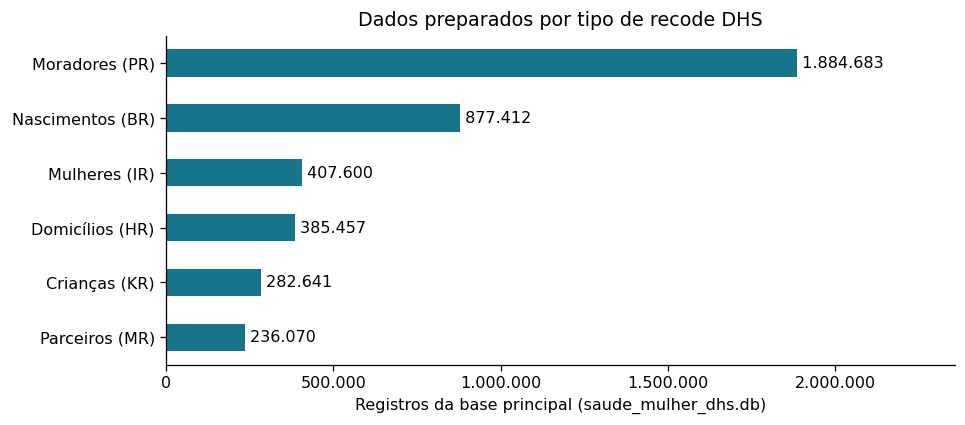

In [4]:
from pathlib import Path
from contextlib import closing
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

raiz = Path.cwd()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 115})
azul = "#16758b"

def exibir(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

with closing(sqlite3.connect(str(raiz / "saude_mulher_dhs.db"))) as banco:
    tipos = {
        "Mulher": "Mulheres (IR)",
        "Nascimento": "Nascimentos (BR)",
        "Domicilio": "Domicílios (HR)",
        "Morador": "Moradores (PR)",
        "Crianca": "Crianças (KR)",
        "Parceiro": "Parceiros (MR)",
    }
    registros = pd.Series({nome: banco.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
                           for tabela, nome in tipos.items()})
    residencia = pd.read_sql_query("""
        SELECT v025 AS residencia, COUNT(*) AS entrevistas
        FROM Mulher GROUP BY v025
    """, banco)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
registros.sort_values().plot.barh(ax=ax, color=azul)
ax.set(xlabel="Registros da base principal (saude_mulher_dhs.db)", title="Dados preparados por tipo de recode DHS",
       xlim=(0, registros.max() * 1.25))
for y, valor in enumerate(registros.sort_values()):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)

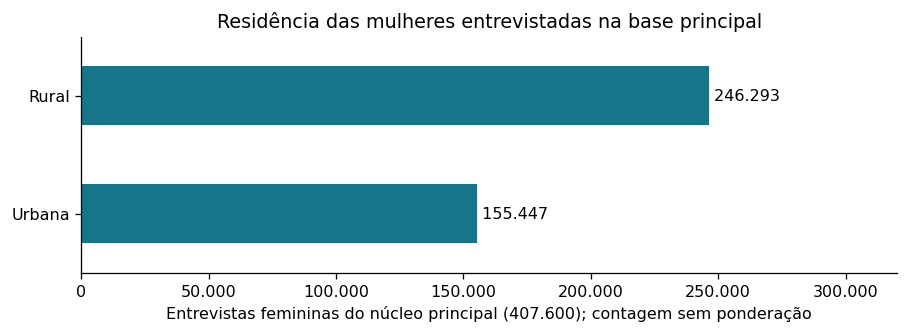

Residência sem informação válida no núcleo principal (Sudão): 5.860 entrevistas.


In [5]:
contagens = residencia.set_index("residencia").entrevistas.reindex([1, 2], fill_value=0)
contagens.index = ["Urbana", "Rural"]
sem_informacao = int(residencia.entrevistas.sum() - contagens.sum())
fig, ax = plt.subplots(figsize=(8, 3))
contagens.plot.barh(ax=ax, color=azul)
ax.set(xlabel="Entrevistas femininas do núcleo principal (407.600); contagem sem ponderação",
       title="Residência das mulheres entrevistadas na base principal", xlim=(0, contagens.max() * 1.3))
for y, valor in enumerate(contagens):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)
print(f"Residência sem informação válida no núcleo principal (Sudão): {sem_informacao:,} entrevistas.".replace(",", "."))

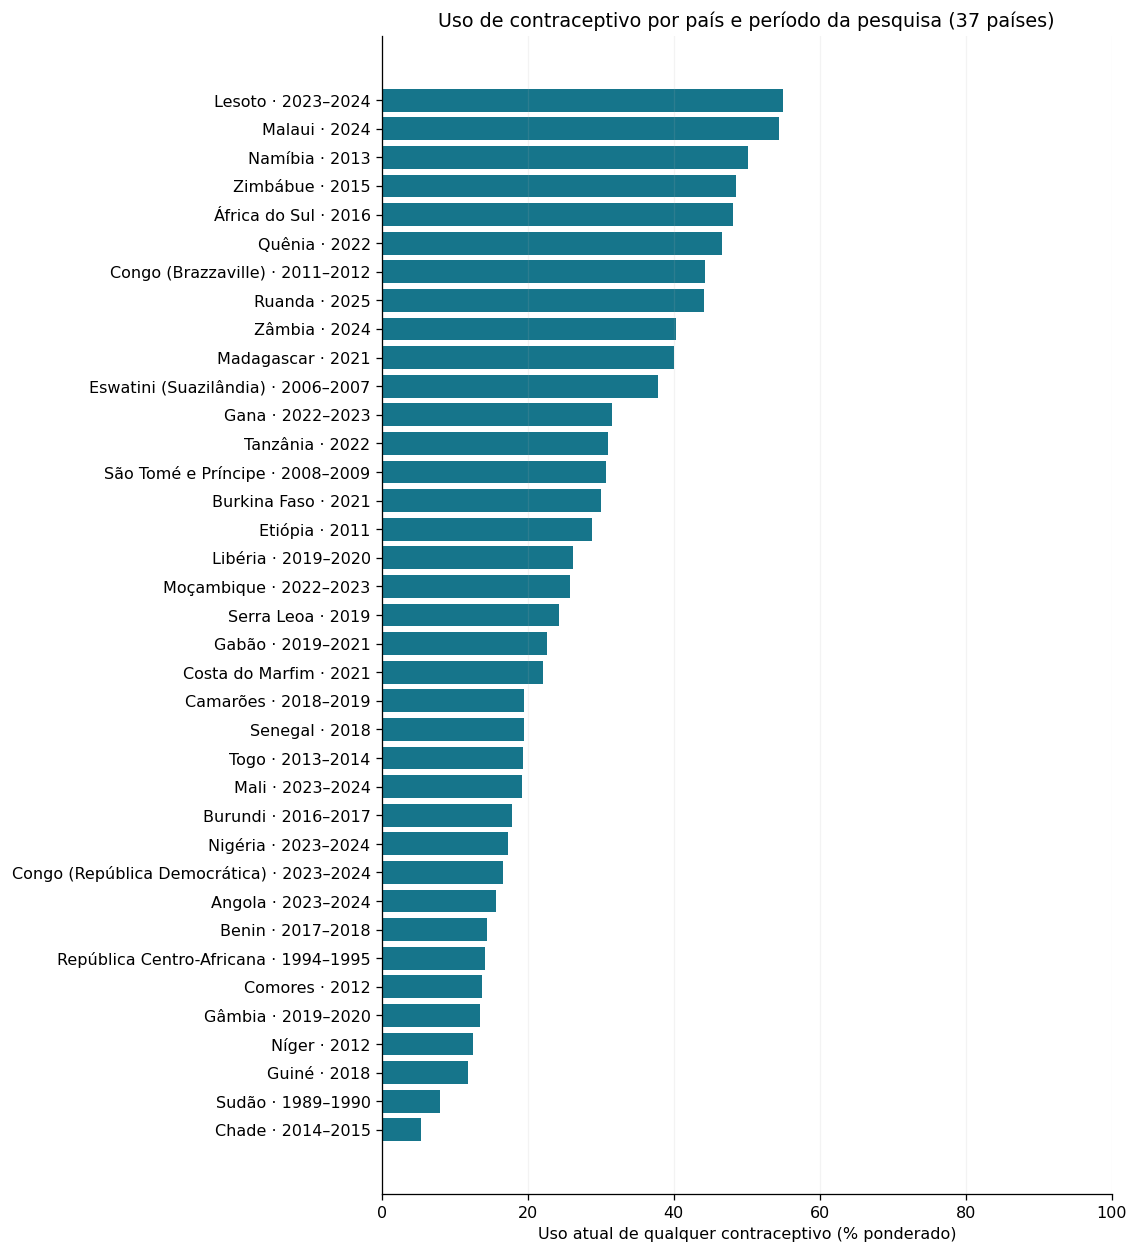

In [6]:
with closing(sqlite3.connect(str(raiz / "saude_mulher_normalizado.db"))) as banco:
    contracepcao = pd.read_sql_query("""
        SELECT p.codigo, p.nome, MIN(e.ano) AS inicio, MAX(e.ano) AS fim,
               ROUND(100.0 * SUM(e.peso * e.usa_metodo) / SUM(e.peso), 2) AS uso_percentual
        FROM Entrevista e
        JOIN Mulher m ON m.id = e.mulher_id
        JOIN Domicilio d ON d.id = m.domicilio_id
        JOIN Levantamento l ON l.id = d.levantamento_id
        JOIN Pais p ON p.codigo = l.pais_codigo
        WHERE e.coorte != 'nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso > 0
        GROUP BY p.codigo, p.nome
    """, banco).sort_values("uso_percentual")

periodos = contracepcao.apply(lambda r: str(int(r.inicio)) if r.inicio == r.fim
                              else f"{int(r.inicio)}–{int(r.fim)}", axis=1)
rotulos = contracepcao.nome + " · " + periodos
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(rotulos, contracepcao.uso_percentual, color=azul)
ax.set(xlim=(0, 100), xlabel="Uso atual de qualquer contraceptivo (% ponderado)",
       title="Uso de contraceptivo por país e período da pesquisa (37 países)")
ax.grid(axis="x", alpha=.15)
exibir(fig)

In [7]:
from pathlib import Path
from time import perf_counter
from statistics import median
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from database_python.relatorio_notebook import (
    abrir_banco, sha256, consultar, detalhes, mostrar, barras, mapa, pares,
    AZUL, LARANJA,
)

conn, origem, hash_origem = abrir_banco(Path.cwd())
nomes = dict(conn.execute("SELECT codigo, nome FROM Pais"))

def consulta(sql, amostra=False):
    return consultar(conn, sql, amostra)

def nomear(df):
    return df.rename(index=nomes).sort_index()

cobertura = consulta("""
SELECT p.codigo, p.nome, l.fase, e.coorte, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL) AS resposta_contraceptiva,
       SUM(d.riqueza IS NOT NULL) AS riqueza_disponivel,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
GROUP BY p.codigo, p.nome, l.fase, e.coorte
ORDER BY p.nome
""")
assert cobertura.codigo.nunique() == 37
assert len(cobertura) == 47

panorama = consulta("""
SELECT p.codigo, p.nome, l.fase, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS entrevistas, SUM(e.usa_metodo IS NOT NULL AND e.peso > 0) AS respostas_validas,
       ROUND(100.0 * SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso > 0 THEN e.peso * e.usa_metodo END) /
       NULLIF(SUM(CASE WHEN e.usa_metodo IS NOT NULL AND e.peso > 0 THEN e.peso END), 0), 2) AS uso_percentual
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
GROUP BY p.codigo, p.nome, l.fase
ORDER BY p.nome
""")
assert len(panorama) == 37 and panorama.uso_percentual.notna().all()
print(f"Cobertura validada: {cobertura.mulheres.sum():,} entrevistas totais em 47 coortes ({cobertura.codigo.nunique()} países); recorte temático de contracepção com {panorama.entrevistas.sum():,} entrevistas.".replace(",", "."))

codigo,nome,fase,coorte,ano_min,ano_max,mulheres,resposta_contraceptiva,riqueza_disponivel,mulheres_com_HR
AO,Angola,81,nucleo_e_contracepcao,2023,2024,14717,14717,14717,14717
BJ,Benin,71,nucleo_e_contracepcao,2017,2018,15928,15928,15928,15928
BF,Burkina Faso,81,nucleo_e_contracepcao,2021,2021,17659,17659,17659,17659
BU,Burundi,71,nucleo_e_contracepcao,2016,2017,17269,17269,17269,17269
CM,Camarões,71,contracepcao,2018,2019,14677,13527,14677,0
CM,Camarões,82,nucleo_exclusivo,2022,2022,6532,0,6532,6532
TD,Chade,71,nucleo_e_contracepcao,2014,2015,17719,17719,17719,17719
KM,Comores,61,nucleo_e_contracepcao,2012,2012,5329,5329,5329,5329
CG,Congo (Brazzaville),61,nucleo_e_contracepcao,2011,2012,10819,10819,10819,10819
CD,Congo (República Democrática),81,nucleo_e_contracepcao,2023,2024,27583,27583,27583,27583


codigo,nome,fase,ano_min,ano_max,entrevistas,respostas_validas,uso_percentual
AO,Angola,81,2023,2024,14717,14717,15.58
BJ,Benin,71,2017,2018,15928,15928,14.41
BF,Burkina Faso,81,2021,2021,17659,17659,30.06
BU,Burundi,71,2016,2017,17269,17269,17.89
CM,Camarões,71,2018,2019,14677,13527,19.52
TD,Chade,71,2014,2015,17719,17719,5.35
KM,Comores,61,2012,2012,5329,5329,13.66
CG,Congo (Brazzaville),61,2011,2012,10819,10819,44.34
CD,Congo (República Democrática),81,2023,2024,27583,27583,16.55
CI,Costa do Marfim,81,2021,2021,14877,14877,22.05


Cobertura validada: 584.004 entrevistas totais em 47 coortes (37 países); recorte temático de contracepção com 510.884 entrevistas.


### 3.2 Domínio e dados processados

Pesquisamos a **saúde da mulher na África Subsaariana**, com foco em contracepção, pré-natal, assistência ao parto, vacinação infantil, contexto intradomiciliar e diferenças de residência, riqueza e escolaridade. A base principal (`saude_mulher_dhs.db`) contém **407.600 entrevistas femininas de 37 países**, acompanhadas pelos demais recodes nos arquivos da pasta `dados/relevantes/`:

| Arquivo compactado | Recode DHS | Registros na base principal | Conteúdo utilizado no esquema relacional |
| --- | --- | ---: | --- |
| `IR.csv.gz` | Individual Recode (`Mulher`, `Entrevista`, `Conhecimento_Metodo`) | 407.600 | Idade, escolaridade, parturição, entrevista, pesos amostrais e conhecimento/uso de métodos contraceptivos |
| `BR.csv.gz` | Birth Recode (`Nascimento`) | 877.412 | Histórico de nascimentos, consultas de pré-natal, local do parto, cesárea e assistência médica/enfermagem |
| `HR.csv.gz` | Household Recode (`Domicilio`) | 385.457 | Moradia (urbana/rural), quintil de riqueza, eletricidade, fonte de água e total de membros |
| `PR.csv.gz` | Household Member Recode (`Morador`) | 1.884.683 | Composição familiar, sexo, idade, escolaridade e relação com o chefe do domicílio |
| `KR.csv.gz` | Children's Recode (`Crianca`, `Crianca_Vacina`) | 282.641 | Crianças menores de 5 anos, diarreia recente, cartão de vacina e histórico das 8 vacinas (`h2`–`h9`) |
| `MR.csv.gz` | Men's Recode (`Parceiro`) | 236.070 | Homens/parceiros entrevistados no domicílio: idade, escolaridade, total de filhos e idade ao primeiro filho |

Na base relacional normalizada (`saude_mulher_normalizado.db`), além dos dados acima, dez levantamentos possuem módulos de contracepção em pesquisas DHS suplementares (`docs/manifesto_contracepcao.json`), acrescentando **176.404 entrevistas femininas** (`coorte = 'contracepcao'`) mantidas separadas do núcleo principal (`407.600 + 176.404 = 584.004` mulheres e entrevistas).

### 3.3 Como os dados foram processados

A preparação foi realizada com `preparar_dados_projeto.py`, `carregar_sqlite.py` e `database_python/relatorio_notebook.py`, que constroem chaves compostas determinísticas (`levantamento_id|cluster|numero|linha|indice`) para vincular domicílios, moradores, mulheres, parceiros, entrevistas, nascimentos, crianças, métodos contraceptivos e vacinas com validação estrita de `PRIMARY KEY`, `FOREIGN KEY`, `UNIQUE` e `CHECK`. O visualizador web é iniciado por `python database_python/server.py` (disponível no [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData)).

# 4. Diagrama ER

![Diagrama ER](docs/Diagrama%20ER.png)

# 5. Diagrama relacional

![Diagrama Relacional](docs/Diagrama%20Relacional.png)

1. **Pais** (`codigo`, `nome`)
   - Chave primária: `codigo`
2. **Levantamento** (`id`, `pais_codigo*`, `fase`)
   - Chave primária: `id` · Chave estrangeira: `pais_codigo` $\rightarrow$ `Pais(codigo)`
3. **Domicilio** (`id`, `levantamento_id*`, `cluster`, `numero`, `regiao`, `residencia`, `riqueza`, `eletricidade`, `fonte_agua`, `membros`, `origem`)
   - Chave primária: `id` · Chave estrangeira: `levantamento_id` $\rightarrow$ `Levantamento(id)`
4. **Morador** (`id`, `domicilio_id*`, `linha`, `sexo`, `idade`, `escolaridade_codigo`, `relacao_chefe_codigo`)
   - Chave primária: `id` · Chave estrangeira: `domicilio_id` $\rightarrow$ `Domicilio(id)`
5. **Mulher** (`id`, `domicilio_id*`, `linha`, `idade`, `escolaridade`, `filhos_nascidos_vivos`, `idade_primeiro_nascimento`)
   - Chave primária: `id` · Chave estrangeira: `domicilio_id` $\rightarrow$ `Domicilio(id)`
6. **Parceiro** (`id`, `domicilio_id*`, `linha`, `idade`, `escolaridade`, `total_filhos`, `idade_primeiro_filho`)
   - Chave primária: `id` · Chave estrangeira: `domicilio_id` $\rightarrow$ `Domicilio(id)`
7. **Entrevista** (`mulher_id*`, `ano`, `mes`, `data_cmc`, `peso`, `usa_metodo`, `coorte`)
   - Chave primária: `mulher_id` · Chave estrangeira: `mulher_id` $\rightarrow$ `Mulher(id)`
8. **Nascimento** (`id`, `mulher_id*`, `indice`, `ano`, `mes`, `data_cmc`, `sexo`, `vivo`, `consultas_prenatal_codigo`, `local_parto_codigo`, `cesarea_codigo`, `assistencia_medico_codigo`, `assistencia_m3b_codigo`, `origem`)
   - Chave primária: `id` · Chave estrangeira: `mulher_id` $\rightarrow$ `Mulher(id)`
9. **Crianca** (`nascimento_id*`, `idade_anos`, `diarreia_codigo`, `cartao_vacina_codigo`)
   - Chave primária: `nascimento_id` · Chave estrangeira: `nascimento_id` $\rightarrow$ `Nascimento(id)`
10. **Vacina_Remedio** (`id`, `codigo`, `nome`)
    - Chave primária: `id`
11. **Crianca_Vacina** (`nascimento_id*`, `vacina_id*`, `status_codigo`) — *Relação M:N com chave primária composta*
    - Chave primária: `(nascimento_id, vacina_id)` · Chaves estrangeiras: `nascimento_id` $\rightarrow$ `Crianca(nascimento_id)`, `vacina_id` $\rightarrow$ `Vacina_Remedio(id)`
12. **Metodo** (`id`, `nome`, `classe`)
    - Chave primária: `id`
13. **Conhecimento_Metodo** (`mulher_id*`, `metodo_id*`, `nivel`) — *Relação M:N com chave primária composta*
    - Chave primária: `(mulher_id, metodo_id)` · Chaves estrangeiras: `mulher_id` $\rightarrow$ `Mulher(id)`, `metodo_id` $\rightarrow$ `Metodo(id)`

# 6. Consultas

Apresentamos a seguir as **10 consultas SQL** estruturadas nas 4 categorias exigidas (2 de seleção e projeção, 3 junções de duas relações, 3 junções de três ou mais relações e 2 agregações sobre junções), seguidas pelas **comparações padronizadas entre áreas urbanas e rurais** (Seção 6.5) e pelo **experimento de otimização de consultas com índice de cobertura** (Seção 6.6). Todas as 13 relações do banco normalizado são exercitadas ao longo das consultas.

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Consulta 1 — Mulheres adolescentes sem escolaridade (`Mulher`)

Seleciona mulheres de 15 a 19 anos sem escolaridade (`escolaridade = 0`), projetando código do país, identificador da mulher, idade atual, idade no primeiro nascimento e total de filhos nascidos vivos.

```sql
SELECT substr(id,1,2) AS pais_codigo, id AS mulher_id, idade, idade_primeiro_nascimento, filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15 AND 19
  AND escolaridade = 0
ORDER BY id
```

pais_codigo,mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
AO,AO_81|100|13|4,18,NaN,0
BF,BF_81|100|273|7,17,NaN,0
BJ,BJ_71|101|116|3,16,NaN,0
BU,BU_71|101|1615|2,18,18.0,1
CD,CD_81|100|122|3,15,NaN,0
CF,CF_31|101|7|11,16,NaN,0
CG,CG_61|103|1|4,19,NaN,0
CI,CI_81|101|4|8,15,NaN,0
CM,CM_71|105|446|2,17,16.0,1
ET,ET_81|102|32|2,19,19.0,1


pais_codigo,registros
AO,457
BF,1087
BJ,956
BU,284
CD,469
CF,520
CG,98
CI,870
CM,506
ET,304


**Resultado:** 21,043 registros. Dados integrais em `r1`/`r2` após execução.

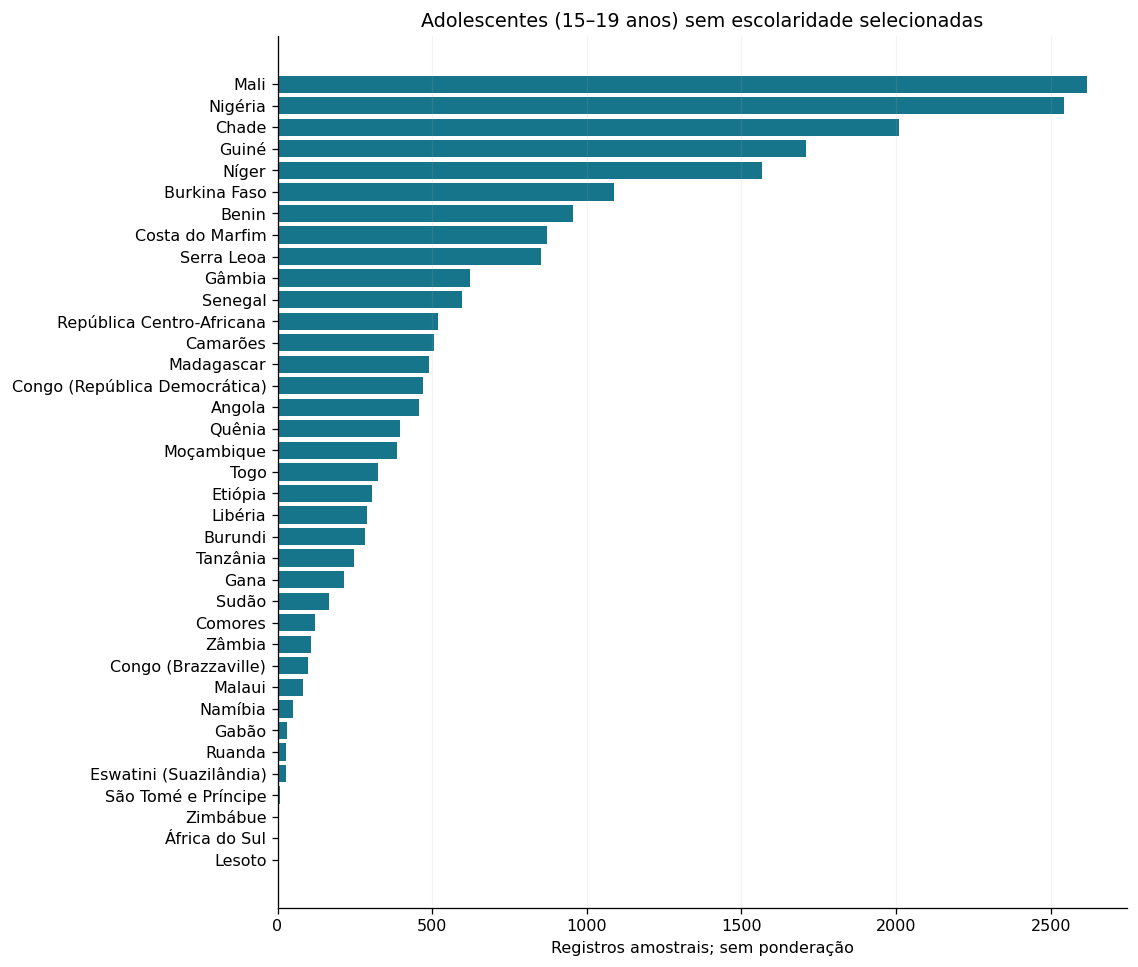

**Resultado:** 21,043 adolescentes sem escolaridade selecionadas em 37 países. Contagens amostrais brutas, sem estimar prevalência populacional.

In [10]:
sql_1 = """
SELECT substr(id,1,2) AS pais_codigo, id AS mulher_id, idade, idade_primeiro_nascimento, filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15 AND 19
  AND escolaridade = 0
ORDER BY id
"""
display(Markdown("```sql\n" + sql_1.strip() + "\n```"))
r1 = consulta(sql_1, amostra=True)
barras(r1.groupby('pais_codigo').size().rename(index=nomes), 'Adolescentes (15–19 anos) sem escolaridade selecionadas', 'Registros amostrais; sem ponderação')
display(Markdown(f"**Resultado:** {len(r1):,} adolescentes sem escolaridade selecionadas em {r1.pais_codigo.nunique()} países. Contagens amostrais brutas, sem estimar prevalência populacional."))

### 6.1.2 Consulta 2 — Domicílios rurais no quintil mais pobre sem eletricidade (`Domicilio`)

Seleciona domicílios localizados em área rural (`residencia = 2`), pertencentes ao quintil mais pobre de riqueza (`riqueza = 1`) e desprovidos de energia elétrica (`eletricidade = 0`), projetando país, identificador do domicílio, código da fonte de água e número de moradores.

```sql
SELECT substr(id,1,2) AS pais_codigo, id AS domicilio_id, fonte_agua, membros
FROM Domicilio
WHERE residencia = 2
  AND riqueza = 1
  AND eletricidade = 0
ORDER BY id
```

pais_codigo,domicilio_id,fonte_agua,membros
AO,AO_81|101|17,43.0,2
BF,BF_81|11|20,21.0,5
BJ,BJ_71|100|130,14.0,3
BU,BU_71|101|1476,32.0,3
CD,CD_81|100|102,42.0,4
CG,CG_61|101|11,13.0,1
CI,CI_81|100|10,21.0,7
CM,CM_82|136|10,42.0,4
ET,ET_81|100|10,42.0,5
GA,GA_71|103|1,43.0,2


pais_codigo,registros
AO,4159
BF,2195
BJ,1840
BU,3305
CD,7091
CG,4987
CI,2554
CM,867
ET,1960
GA,2394


**Resultado:** 75,029 registros. Dados integrais em `r1`/`r2` após execução.

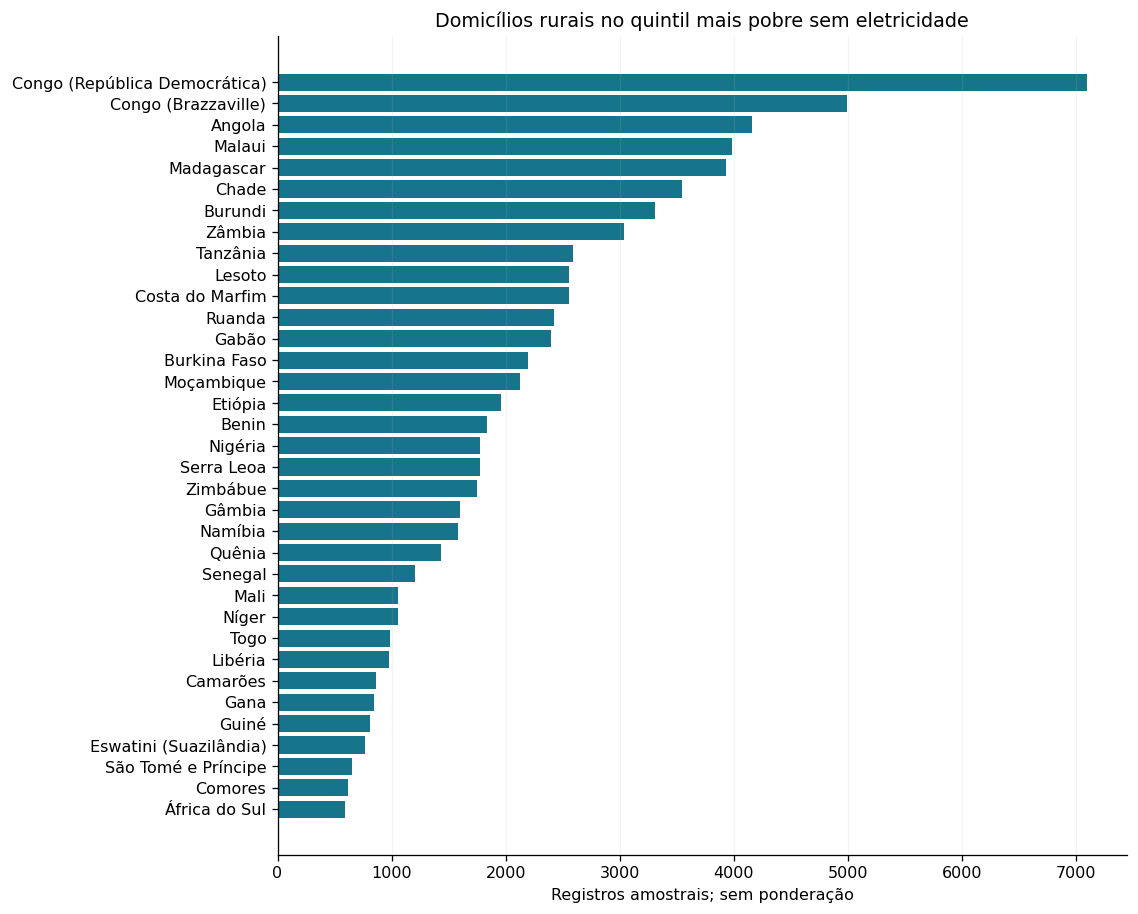

**Resultado:** 75,029 domicílios rurais vulneráveis selecionados em 35 países (Sudão não possui variável de residência/eletricidade neste recorte).

In [11]:
sql_2 = """
SELECT substr(id,1,2) AS pais_codigo, id AS domicilio_id, fonte_agua, membros
FROM Domicilio
WHERE residencia = 2
  AND riqueza = 1
  AND eletricidade = 0
ORDER BY id
"""
display(Markdown("```sql\n" + sql_2.strip() + "\n```"))
r2 = consulta(sql_2, amostra=True)
barras(r2.groupby('pais_codigo').size().rename(index=nomes), 'Domicílios rurais no quintil mais pobre sem eletricidade', 'Registros amostrais; sem ponderação')
display(Markdown(f"**Resultado:** {len(r2):,} domicílios rurais vulneráveis selecionados em {r2.pais_codigo.nunique()} países (Sudão não possui variável de residência/eletricidade neste recorte)."))

## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Consulta 3 — Escolaridade feminina e parturição por residência (`Mulher ⋈ Domicilio`)

Relaciona `Mulher` e `Domicilio` para comparar a proporção amostral de mulheres sem escolaridade, a idade média e o número médio de filhos nascidos vivos entre zonas urbanas e rurais no núcleo principal.

```sql
SELECT substr(d.id,1,2) AS pais_codigo,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       ROUND(AVG(m.idade),2) AS idade_media,
       ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
       ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
WHERE d.origem != 'IR_completo'
  AND d.residencia IN (1, 2)
GROUP BY substr(d.id,1,2), d.residencia
ORDER BY pais_codigo, d.residencia
```

pais_codigo,residencia,mulheres,idade_media,filhos_medios,percentual_sem_escola
AO,Urbano,9066,26.87,2.19,10.07
AO,Rural,5651,27.99,3.17,40.93
BF,Urbano,6227,27.98,2.01,36.29
BF,Rural,11432,29.23,3.17,69.93
BJ,Urbano,7045,28.59,2.51,42.60
BJ,Rural,8883,28.46,3.17,64.85
BU,Urbano,3671,27.20,1.94,13.38
BU,Rural,13598,28.41,2.82,39.62
CD,Urbano,9146,27.41,2.30,5.18
CD,Rural,18437,28.40,3.25,23.77


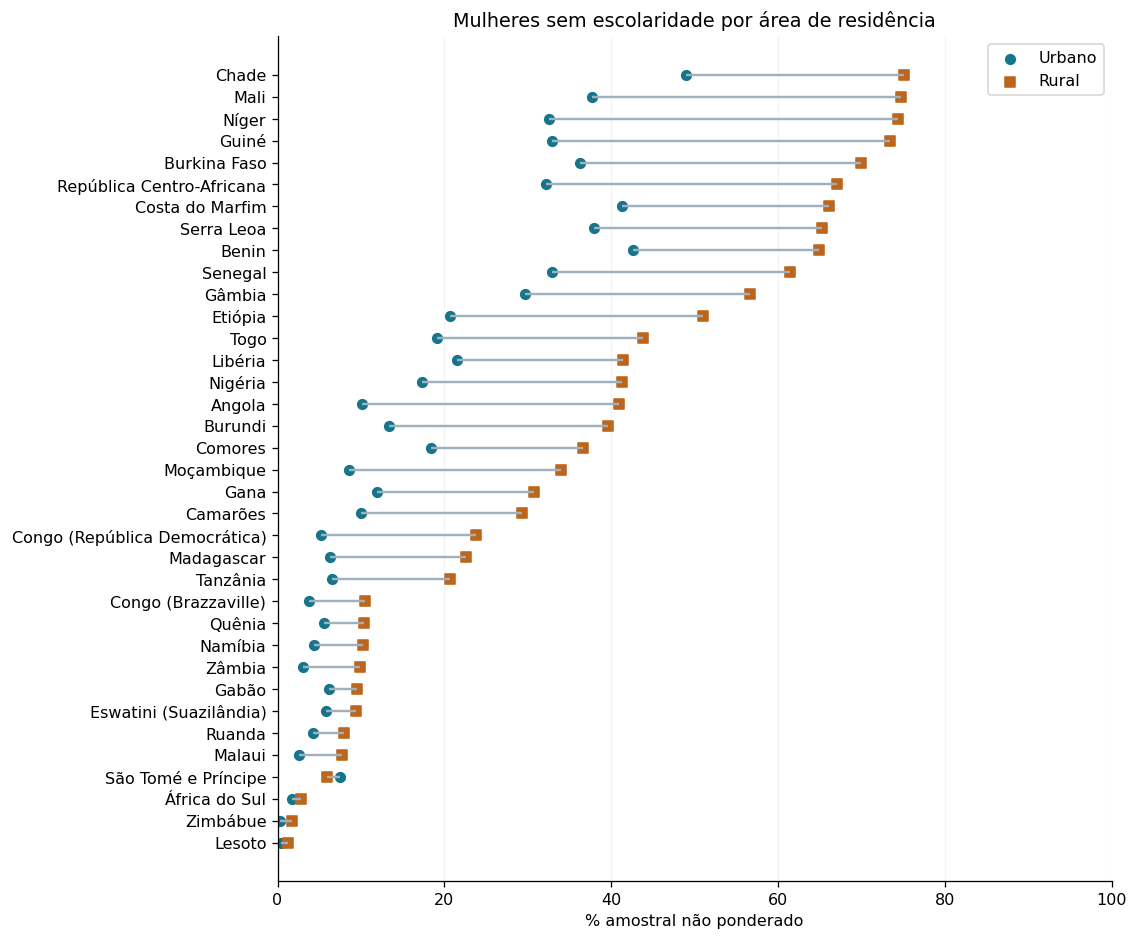

**Resultado:** a proporção de mulheres sem escolaridade é maior no meio rural em **35 de 36** países com informação de residência.

In [12]:
sql_3 = """
SELECT substr(d.id,1,2) AS pais_codigo,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       ROUND(AVG(m.idade),2) AS idade_media,
       ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
       ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
WHERE d.origem != 'IR_completo'
  AND d.residencia IN (1, 2)
GROUP BY substr(d.id,1,2), d.residencia
ORDER BY pais_codigo, d.residencia
"""
display(Markdown("```sql\n" + sql_3.strip() + "\n```"))
r3 = consulta(sql_3, amostra=False)
pares(nomear(r3.pivot(index='pais_codigo', columns='residencia', values='percentual_sem_escola')), 'Urbano', 'Rural', 'Mulheres sem escolaridade por área de residência', '% amostral não ponderado')
comparacao_q3 = r3.pivot(index='pais_codigo', columns='residencia', values='percentual_sem_escola').dropna()
maior_q3 = int((comparacao_q3.Rural > comparacao_q3.Urbano).sum())
display(Markdown(f"**Resultado:** a proporção de mulheres sem escolaridade é maior no meio rural em **{maior_q3} de {len(comparacao_q3)}** países com informação de residência."))

### 6.2.2 Consulta 4 — Uso atual ponderado de contraceptivos por escolaridade (`Entrevista ⋈ Mulher`)

Combina `Entrevista` e `Mulher` para estimar o uso percentual ponderado (`v005`) de métodos contraceptivos segundo os quatro níveis padronizados de escolaridade feminina (`0`: Nenhuma, `1`: Primário, `2`: Secundário, `3`: Superior), utilizando uma pesquisa temática por país.

```sql
SELECT substr(m.id,1,2) AS pais_codigo, m.escolaridade,
       COUNT(*) AS respostas_validas,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND m.escolaridade IS NOT NULL
GROUP BY substr(m.id,1,2), m.escolaridade
ORDER BY pais_codigo, m.escolaridade
```

pais_codigo,escolaridade,respostas_validas,percentual_uso_ponderado
AO,0,3226,5.31
AO,1,4149,10.82
AO,2,6747,20.30
AO,3,595,28.28
BF,0,10254,29.04
BF,1,2515,31.30
BF,2,4548,30.46
BF,3,342,43.92
BJ,0,8762,12.42
BJ,1,3116,14.57


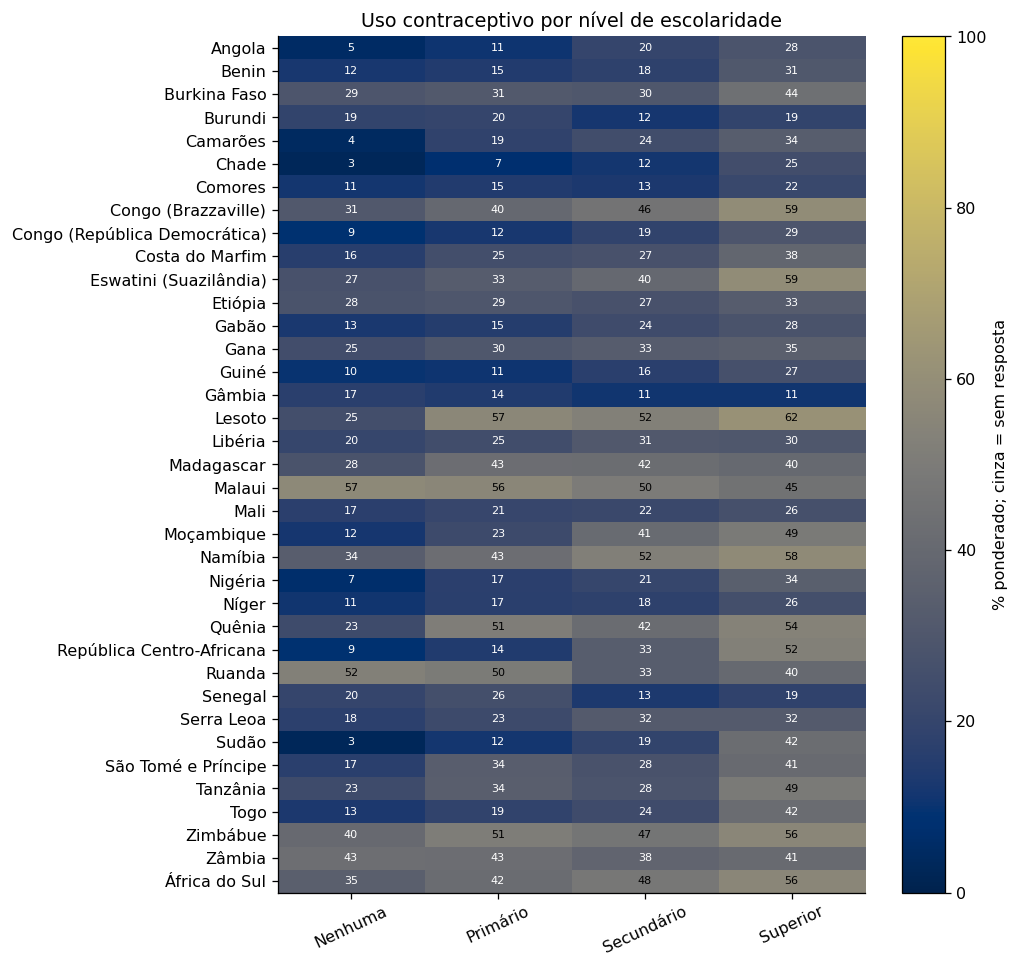

**Resultado:** o uso contraceptivo ponderado é maior entre mulheres com ensino superior do que entre mulheres sem escolaridade em **31 de 37** países.

In [13]:
sql_4 = """
SELECT substr(m.id,1,2) AS pais_codigo, m.escolaridade,
       COUNT(*) AS respostas_validas,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND m.escolaridade IS NOT NULL
GROUP BY substr(m.id,1,2), m.escolaridade
ORDER BY pais_codigo, m.escolaridade
"""
display(Markdown("```sql\n" + sql_4.strip() + "\n```"))
r4 = consulta(sql_4, amostra=False)
mapa(nomear(r4.pivot(index='pais_codigo', columns='escolaridade', values='percentual_uso_ponderado')).rename(columns={0:'Nenhuma', 1:'Primário', 2:'Secundário', 3:'Superior'}), 'Uso contraceptivo por nível de escolaridade', '% ponderado; cinza = sem resposta')
extremos_q4 = r4[r4.escolaridade.isin([0, 3])].pivot(index='pais_codigo', columns='escolaridade', values='percentual_uso_ponderado').dropna()
display(Markdown(f"**Resultado:** o uso contraceptivo ponderado é maior entre mulheres com ensino superior do que entre mulheres sem escolaridade em **{int((extremos_q4[3] > extremos_q4[0]).sum())} de {len(extremos_q4)}** países."))

### 6.2.3 Consulta 5 — Conhecimento detalhado dos nove métodos contraceptivos (`Conhecimento_Metodo ⋈ Metodo`)

Une a relação associativa M:N `Conhecimento_Metodo` ao catálogo `Metodo` para mensurar a proporção de mulheres que conhecem cada um dos 7 métodos modernos e 2 tradicionais por levantamento.

```sql
SELECT substr(k.mulher_id,1,2) AS pais_codigo,
       substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,
       t.nome, t.classe,
       COUNT(*) AS respostas_validas,
       SUM(k.nivel > 0) AS conhecem,
       ROUND(100.0*SUM(k.nivel > 0)/COUNT(*),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id = k.metodo_id
GROUP BY substr(k.mulher_id,1,2), levantamento, t.id, t.nome, t.classe
ORDER BY pais_codigo, t.id
```

pais_codigo,levantamento,nome,classe,respostas_validas,conhecem,percentual_conhecimento
AO,AO_81,Pílula,Moderno,14717,9755,66.28
AO,AO_81,DIU,Moderno,14717,5486,37.28
AO,AO_81,Injetáveis,Moderno,14717,9511,64.63
AO,AO_81,Preservativo masculino,Moderno,14717,11692,79.45
AO,AO_81,Esterilização feminina,Moderno,14717,3215,21.85
AO,AO_81,Esterilização masculina,Moderno,14717,2307,15.68
AO,AO_81,Abstinência periódica,Tradicional,14717,4959,33.70
AO,AO_81,Coito interrompido,Tradicional,14717,5447,37.01
BF,BF_81,Pílula,Moderno,17659,15830,89.64
BF,BF_81,DIU,Moderno,17659,10978,62.17


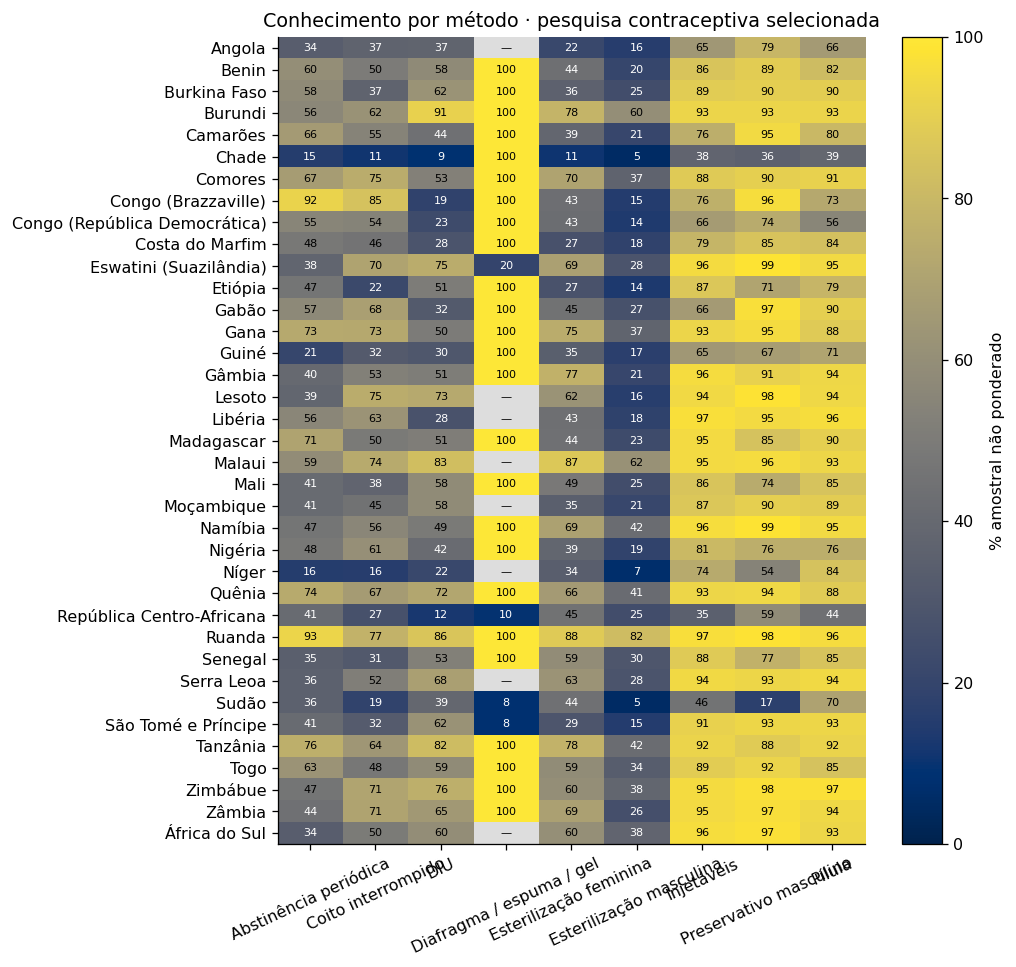

**Resultado:** respostas válidas de conhecimento para os 9 métodos em **37 países** (325 agregados levantamento×método). Métodos modernos como pílula, injetáveis e preservativo masculino apresentam as maiores taxas médias de reconhecimento.

In [14]:
sql_5 = """
SELECT substr(k.mulher_id,1,2) AS pais_codigo,
       substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,
       t.nome, t.classe,
       COUNT(*) AS respostas_validas,
       SUM(k.nivel > 0) AS conhecem,
       ROUND(100.0*SUM(k.nivel > 0)/COUNT(*),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id = k.metodo_id
GROUP BY substr(k.mulher_id,1,2), levantamento, t.id, t.nome, t.classe
ORDER BY pais_codigo, t.id
"""
display(Markdown("```sql\n" + sql_5.strip() + "\n```"))
r5 = consulta(sql_5, amostra=False)
escolha = panorama.assign(levantamento=panorama.codigo + '_' + panorama.fase.astype(str))[['codigo', 'levantamento']]
visual = r5.merge(escolha, on='levantamento', validate='many_to_one')
mapa(nomear(visual.pivot(index='pais_codigo', columns='nome', values='percentual_conhecimento')), 'Conhecimento por método · pesquisa contraceptiva selecionada', '% amostral não ponderado')
display(Markdown(f"**Resultado:** respostas válidas de conhecimento para os 9 métodos em **{r5.pais_codigo.nunique()} países** ({len(r5):,} agregados levantamento×método). Métodos modernos como pílula, injetáveis e preservativo masculino apresentam as maiores taxas médias de reconhecimento."))

## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Consulta 6 — Condições socioeconômicas domiciliares, chefia feminina e desigualdade entre mulher e parceiro (`Entrevista ⋈ Mulher ⋈ Parceiro ⋈ Morador ⋈ Domicilio ⋈ Levantamento ⋈ Pais`)

Integra as três especializações de `Pessoa` do Diagrama ER (`Mulher`, `Parceiro` e `Morador`) ao contexto de `Domicilio`, `Levantamento` e `Pais` para comparar, entre áreas urbanas e rurais, a privação material (quintil mais pobre e falta de eletricidade), a proporção de mulheres e parceiros sem escolaridade, a idade média ao primeiro filho de ambos e o percentual de domicílios chefiados por mulheres (`relacao_chefe_codigo = 1` e `sexo = 2` em `Morador`).

```sql
WITH parceiros_area AS (
  SELECT l.pais_codigo AS codigo, d.residencia,
         COUNT(*) AS parceiros,
         ROUND(100.0*SUM(pr.escolaridade=0)/NULLIF(SUM(pr.escolaridade IS NOT NULL),0),2) AS parceiro_sem_escola_pct,
         ROUND(AVG(pr.idade_primeiro_filho),2) AS idade_1o_filho_parceiro
  FROM Parceiro pr
  JOIN Domicilio d ON d.id = pr.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  WHERE d.residencia IN (1, 2)
  GROUP BY l.pais_codigo, d.residencia
),
chefia_area AS (
  SELECT l.pais_codigo AS codigo, d.residencia,
         ROUND(100.0*SUM(mo.sexo=2)/NULLIF(COUNT(*),0),2) AS chefia_feminina_pct
  FROM Morador mo
  JOIN Domicilio d ON d.id = mo.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  WHERE mo.relacao_chefe_codigo = 1 AND mo.sexo IN (1, 2) AND d.residencia IN (1, 2)
  GROUP BY l.pais_codigo, d.residencia
)
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       COALESCE(pa.parceiros, 0) AS parceiros_entrevistados,
       ROUND(100.0*SUM(d.riqueza=1)/NULLIF(SUM(d.riqueza IS NOT NULL),0),2) AS percentual_quintil_1,
       ROUND(100.0*SUM(d.eletricidade=0)/NULLIF(SUM(d.eletricidade IS NOT NULL),0),2) AS percentual_sem_eletricidade,
       ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola,
       pa.parceiro_sem_escola_pct,
       ROUND(AVG(m.idade_primeiro_nascimento),2) AS idade_1o_filho_mulher,
       pa.idade_1o_filho_parceiro,
       ca.chefia_feminina_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
LEFT JOIN parceiros_area pa ON pa.codigo = p.codigo AND pa.residencia = d.residencia
LEFT JOIN chefia_area ca ON ca.codigo = p.codigo AND ca.residencia = d.residencia
WHERE e.coorte != 'contracepcao'
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
```

codigo,nome,residencia,mulheres,parceiros_entrevistados,percentual_quintil_1,percentual_sem_eletricidade,percentual_sem_escola,parceiro_sem_escola_pct,idade_1o_filho_mulher,idade_1o_filho_parceiro,chefia_feminina_pct
AO,Angola,Urbano,9066,4043,1.18,19.17,10.07,4.23,18.95,22.77,35.69
AO,Angola,Rural,5651,2561,52.45,87.65,40.93,19.17,18.74,22.06,37.63
BJ,Benin,Urbano,7045,3383,13.03,42.19,42.60,26.37,20.48,25.36,25.30
BJ,Benin,Rural,8883,4212,21.82,77.43,64.85,46.75,19.30,24.23,24.19
BF,Burkina Faso,Urbano,6227,2819,1.08,45.85,36.29,28.73,20.16,26.85,18.58
BF,Burkina Faso,Rural,11432,4901,24.51,93.19,69.93,60.27,19.11,25.20,10.69
BU,Burundi,Urbano,3671,1764,3.84,40.42,13.38,10.49,21.47,27.04,27.37
BU,Burundi,Rural,13598,5788,21.00,97.56,39.62,30.65,20.69,24.50,29.22
CM,Camarões,Urbano,3755,3702,2.45,12.52,9.99,6.05,NaN,26.02,28.90
CM,Camarões,Rural,2777,3276,35.22,64.60,29.28,14.13,NaN,24.65,24.01


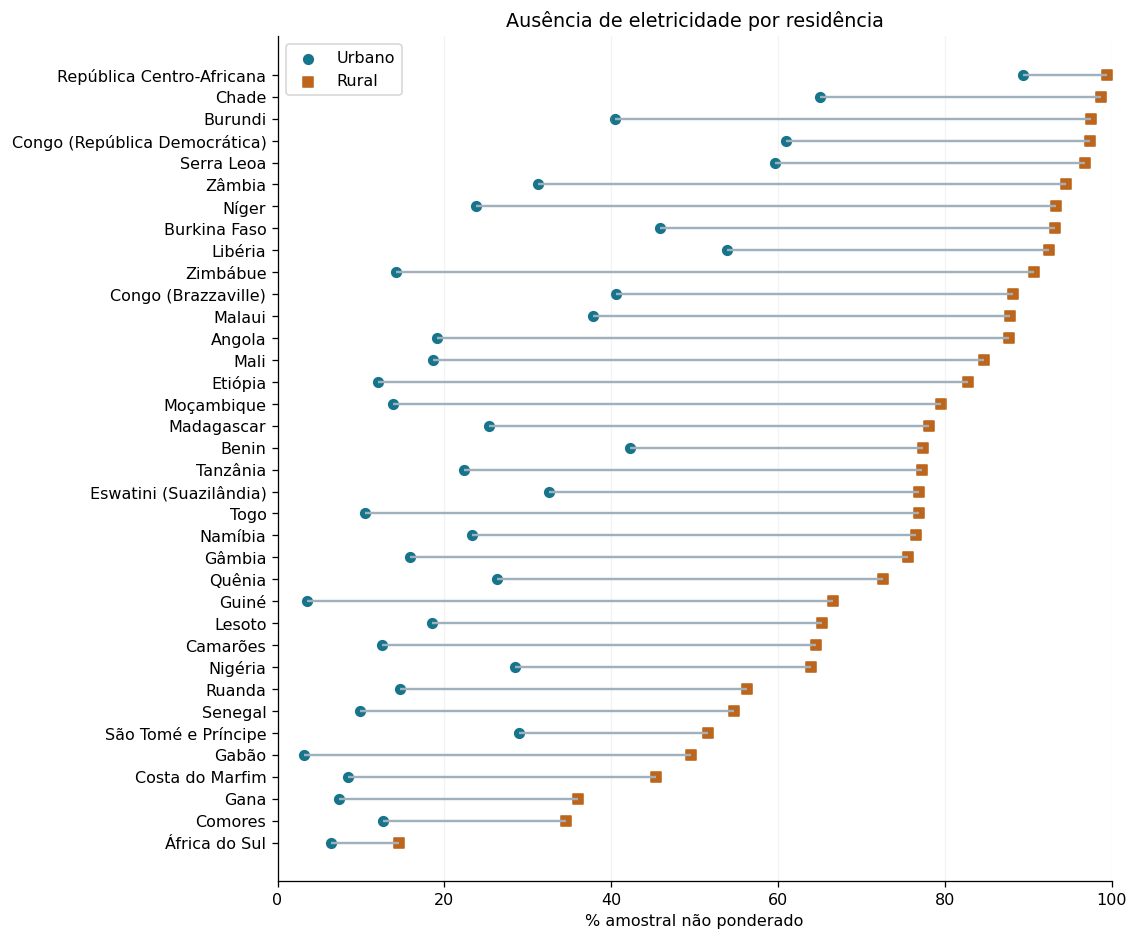

**Resultado:** a falta de eletricidade é maior no meio rural em **36 de 36** países; a proporção de mulheres sem escolaridade supera a dos parceiros (`MR`) em **60 de 72** estratos país×residência, e a idade média ao primeiro filho das mulheres (~19–20 anos) ocorre cerca de 4 a 6 anos antes da registrada entre os parceiros (~23–26 anos).

In [15]:
sql_6 = """
WITH parceiros_area AS (
  SELECT l.pais_codigo AS codigo, d.residencia,
         COUNT(*) AS parceiros,
         ROUND(100.0*SUM(pr.escolaridade=0)/NULLIF(SUM(pr.escolaridade IS NOT NULL),0),2) AS parceiro_sem_escola_pct,
         ROUND(AVG(pr.idade_primeiro_filho),2) AS idade_1o_filho_parceiro
  FROM Parceiro pr
  JOIN Domicilio d ON d.id = pr.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  WHERE d.residencia IN (1, 2)
  GROUP BY l.pais_codigo, d.residencia
),
chefia_area AS (
  SELECT l.pais_codigo AS codigo, d.residencia,
         ROUND(100.0*SUM(mo.sexo=2)/NULLIF(COUNT(*),0),2) AS chefia_feminina_pct
  FROM Morador mo
  JOIN Domicilio d ON d.id = mo.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  WHERE mo.relacao_chefe_codigo = 1 AND mo.sexo IN (1, 2) AND d.residencia IN (1, 2)
  GROUP BY l.pais_codigo, d.residencia
)
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       COALESCE(pa.parceiros, 0) AS parceiros_entrevistados,
       ROUND(100.0*SUM(d.riqueza=1)/NULLIF(SUM(d.riqueza IS NOT NULL),0),2) AS percentual_quintil_1,
       ROUND(100.0*SUM(d.eletricidade=0)/NULLIF(SUM(d.eletricidade IS NOT NULL),0),2) AS percentual_sem_eletricidade,
       ROUND(100.0*SUM(m.escolaridade=0)/NULLIF(SUM(m.escolaridade IS NOT NULL),0),2) AS percentual_sem_escola,
       pa.parceiro_sem_escola_pct,
       ROUND(AVG(m.idade_primeiro_nascimento),2) AS idade_1o_filho_mulher,
       pa.idade_1o_filho_parceiro,
       ca.chefia_feminina_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
LEFT JOIN parceiros_area pa ON pa.codigo = p.codigo AND pa.residencia = d.residencia
LEFT JOIN chefia_area ca ON ca.codigo = p.codigo AND ca.residencia = d.residencia
WHERE e.coorte != 'contracepcao'
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
"""
display(Markdown("```sql\n" + sql_6.strip() + "\n```"))
r6 = consulta(sql_6, amostra=False)
pares(r6.pivot(index='nome', columns='residencia', values='percentual_sem_eletricidade'), 'Urbano', 'Rural', 'Ausência de eletricidade por residência', '% amostral não ponderado')
material_q6 = r6.pivot(index='codigo', columns='residencia', values='percentual_sem_eletricidade').dropna()
gap_genero = r6.dropna(subset=['percentual_sem_escola', 'parceiro_sem_escola_pct'])
maior_f_sem_escola = int((gap_genero.percentual_sem_escola > gap_genero.parceiro_sem_escola_pct).sum())
display(Markdown(
    f"**Resultado:** a falta de eletricidade é maior no meio rural em **{int((material_q6.Rural > material_q6.Urbano).sum())} de {len(material_q6)}** países; "
    f"a proporção de mulheres sem escolaridade supera a dos parceiros (`MR`) em **{maior_f_sem_escola} de {len(gap_genero)}** estratos país×residência, "
    f"e a idade média ao primeiro filho das mulheres (~19–20 anos) ocorre cerca de 4 a 6 anos antes da registrada entre os parceiros (~23–26 anos)."
))

### 6.3.2 Consulta 7 — Assistência ao pré-natal, parto institucional e cesáreas (`Entrevista ⋈ Mulher ⋈ Domicilio ⋈ Levantamento ⋈ Pais ⋈ Nascimento`)

Analisa o nascimento mais recente ocorrido nos últimos 60 meses (`indice = 1` e `e.data_cmc - n.data_cmc BETWEEN 0 AND 59`), articulando a cobertura de resposta do pré-natal (`consultas_prenatal_codigo`), a proporção de partos em estabelecimentos de saúde (`local_parto_codigo BETWEEN 20 AND 39`), a assistência no parto por médico ou enfermeira/parteira qualificada (`assistencia_medico_codigo = 1` ou `assistencia_m3b_codigo = 1`) e a taxa de cesáreas (`cesarea_codigo = 1`) por residência.

```sql
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS nascimentos_recentes,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS respostas_validas,
       ROUND(100.0*SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END)/COUNT(*),2) AS cobertura_resposta_percentual,
       ROUND(100.0*SUM(CASE WHEN n.local_parto_codigo BETWEEN 20 AND 39 THEN 1 ELSE 0 END)/NULLIF(SUM(n.local_parto_codigo BETWEEN 10 AND 96),0),2) AS parto_institucional_pct,
       ROUND(100.0*SUM(CASE WHEN n.assistencia_medico_codigo=1 OR n.assistencia_m3b_codigo=1 THEN 1 ELSE 0 END)/NULLIF(SUM(n.assistencia_medico_codigo IS NOT NULL OR n.assistencia_m3b_codigo IS NOT NULL),0),2) AS assistencia_qualificada_pct,
       ROUND(100.0*SUM(CASE WHEN n.cesarea_codigo=1 THEN 1 ELSE 0 END)/NULLIF(SUM(n.cesarea_codigo IN (0,1)),0),2) AS cesarea_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
```

codigo,nome,residencia,nascimentos_recentes,respostas_validas,cobertura_resposta_percentual,parto_institucional_pct,assistencia_qualificada_pct,cesarea_pct
AO,Angola,Urbano,4208,2992,71.10,67.01,71.24,9.34
AO,Angola,Rural,3617,2865,79.21,22.78,25.40,2.36
BJ,Benin,Urbano,3628,3513,96.83,90.96,17.06,8.90
BJ,Benin,Rural,5349,5237,97.91,80.41,11.53,3.81
BF,Burkina Faso,Urbano,2777,1859,66.94,97.07,5.80,10.19
BF,Burkina Faso,Rural,6515,4525,69.46,92.95,2.31,4.86
BU,Burundi,Urbano,1478,1476,99.86,88.50,27.33,17.47
BU,Burundi,Rural,7161,7158,99.96,79.91,9.43,4.44
CM,Camarões,Urbano,1561,1122,71.88,NaN,NaN,NaN
CM,Camarões,Rural,1524,1202,78.87,NaN,NaN,NaN


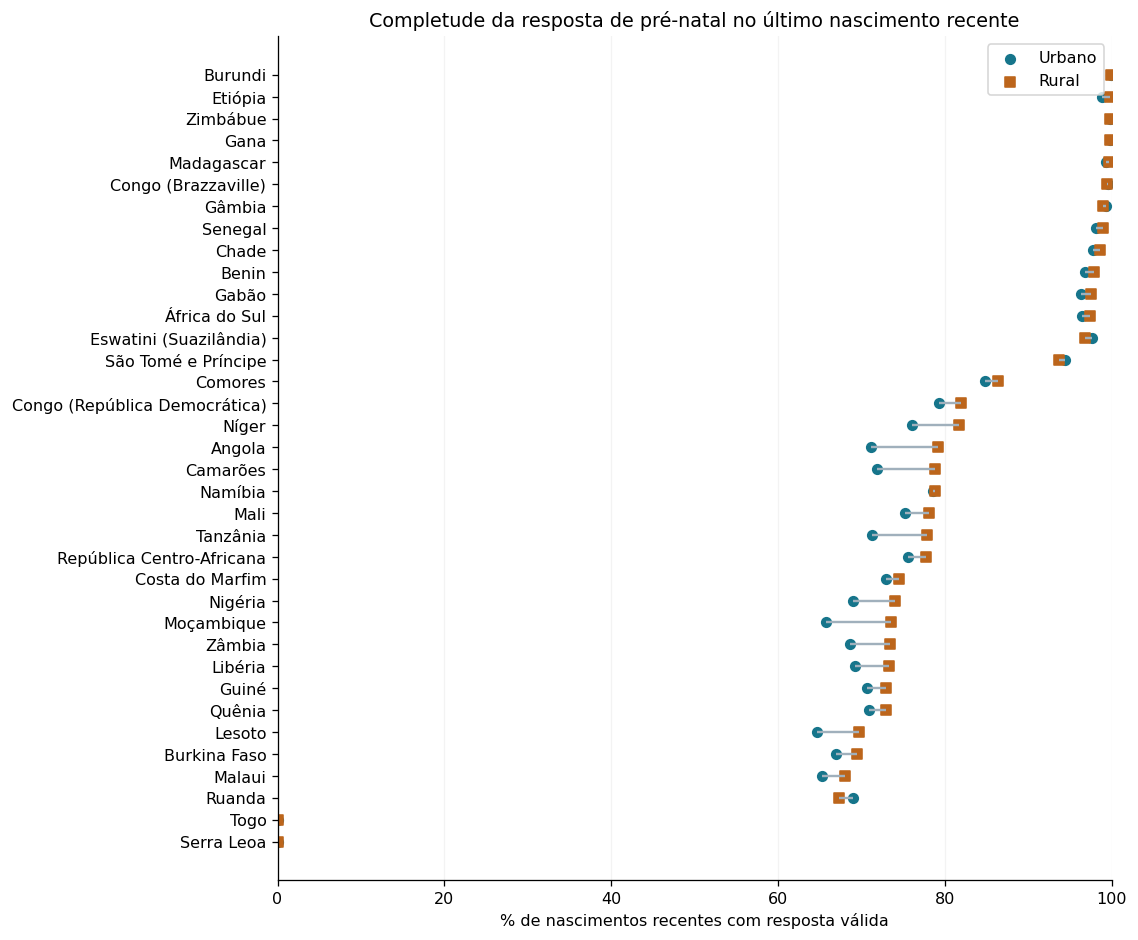

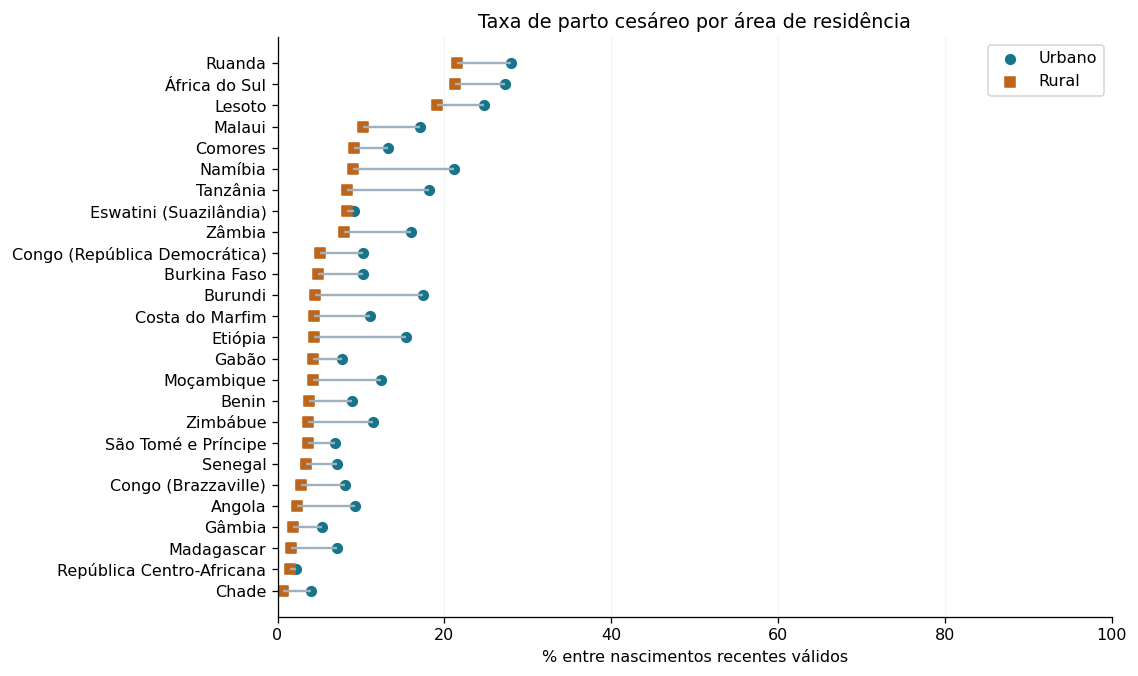

**Resultado:** nascimentos recentes avaliados em **36 países**, com completude de resposta de pré-natal entre **0.0% e 100.0%**. A taxa de cesáreas é superior na zona urbana em **26 de 26** países, permanecendo abaixo de 5% no meio rural na grande maioria dos países analisados.

In [16]:
sql_7 = """
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS nascimentos_recentes,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS respostas_validas,
       ROUND(100.0*SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END)/COUNT(*),2) AS cobertura_resposta_percentual,
       ROUND(100.0*SUM(CASE WHEN n.local_parto_codigo BETWEEN 20 AND 39 THEN 1 ELSE 0 END)/NULLIF(SUM(n.local_parto_codigo BETWEEN 10 AND 96),0),2) AS parto_institucional_pct,
       ROUND(100.0*SUM(CASE WHEN n.assistencia_medico_codigo=1 OR n.assistencia_m3b_codigo=1 THEN 1 ELSE 0 END)/NULLIF(SUM(n.assistencia_medico_codigo IS NOT NULL OR n.assistencia_m3b_codigo IS NOT NULL),0),2) AS assistencia_qualificada_pct,
       ROUND(100.0*SUM(CASE WHEN n.cesarea_codigo=1 THEN 1 ELSE 0 END)/NULLIF(SUM(n.cesarea_codigo IN (0,1)),0),2) AS cesarea_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
"""
display(Markdown("```sql\n" + sql_7.strip() + "\n```"))
r7 = consulta(sql_7, amostra=False)
pares(r7.pivot(index='nome', columns='residencia', values='cobertura_resposta_percentual'), 'Urbano', 'Rural', 'Completude da resposta de pré-natal no último nascimento recente', '% de nascimentos recentes com resposta válida')
pares(r7.pivot(index='nome', columns='residencia', values='cesarea_pct'), 'Urbano', 'Rural', 'Taxa de parto cesáreo por área de residência', '% entre nascimentos recentes válidos')
ces_comp = r7.pivot(index='codigo', columns='residencia', values='cesarea_pct').dropna()
display(Markdown(
    f"**Resultado:** nascimentos recentes avaliados em **{r7.codigo.nunique()} países**, com completude de resposta de pré-natal entre "
    f"**{r7.cobertura_resposta_percentual.min():.1f}% e {r7.cobertura_resposta_percentual.max():.1f}%**. "
    f"A taxa de cesáreas é superior na zona urbana em **{int((ces_comp.Urbano > ces_comp.Rural).sum())} de {len(ces_comp)}** países, "
    f"permanecendo abaixo de 5% no meio rural na grande maioria dos países analisados."
))

### 6.3.3 Consulta 8 — Conhecimento versus uso contraceptivo e cobertura vacinal infantil (`Conhecimento_Metodo ⋈ Metodo ⋈ Entrevista ⋈ Mulher ⋈ Domicilio ⋈ Levantamento ⋈ Pais` e `Crianca ⋈ Crianca_Vacina ⋈ Vacina_Remedio`)

Compara o conhecimento de métodos modernos e o uso atual de qualquer método no mesmo denominador ponderado, sem duplicar mulheres, articulando esse indicador à cobertura vacinal infantil das 8 vacinas do calendário básico (`Vacina_Remedio` e `Crianca_Vacina`, com `status_codigo IN (1, 2, 3)`) e à vacinação contra sarampo/rubéola (`h9`) nos respectivos países. Inclui também o teste de sensibilidade semântica excluindo o código `7` do DHS.

```sql
WITH conhecimento AS (
  SELECT k.mulher_id,
         CASE WHEN MAX(k.nivel > 0) = 1 THEN 1 WHEN COUNT(*) = 7 THEN 0 END AS conhece_moderno
  FROM Conhecimento_Metodo k
  JOIN Metodo t ON t.id = k.metodo_id
  WHERE t.classe = 'Moderno'
  GROUP BY k.mulher_id
),
vacinacao_pais AS (
  SELECT l.pais_codigo AS codigo,
         COUNT(DISTINCT c.nascimento_id) AS criancas_avaliadas,
         ROUND(100.0*SUM(CASE WHEN cv.status_codigo IN (1,2,3) THEN 1 ELSE 0 END)/NULLIF(COUNT(cv.vacina_id),0),2) AS doses_aplicadas_pct,
         ROUND(100.0*SUM(CASE WHEN v.codigo='h9' AND cv.status_codigo IN (1,2,3) THEN 1 ELSE 0 END)/NULLIF(SUM(CASE WHEN v.codigo='h9' THEN 1 ELSE 0 END),0),2) AS sarampo_pct
  FROM Crianca c
  JOIN Nascimento n ON n.id = c.nascimento_id
  JOIN Mulher m ON m.id = n.mulher_id
  JOIN Domicilio d ON d.id = m.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  JOIN Crianca_Vacina cv ON cv.nascimento_id = c.nascimento_id
  JOIN Vacina_Remedio v ON v.id = cv.vacina_id
  GROUP BY l.pais_codigo
)
SELECT p.codigo, p.nome,
       COUNT(*) AS mulheres_respostas_validas,
       ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS percentual_conhece_moderno,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_qualquer,
       vp.criancas_avaliadas,
       vp.doses_aplicadas_pct,
       vp.sarampo_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN conhecimento k ON k.mulher_id = m.id
LEFT JOIN vacinacao_pais vp ON vp.codigo = p.codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND k.conhece_moderno IS NOT NULL
GROUP BY p.codigo, p.nome
ORDER BY p.nome
```

codigo,nome,mulheres_respostas_validas,percentual_conhece_moderno,percentual_uso_qualquer,criancas_avaliadas,doses_aplicadas_pct,sarampo_pct
AO,Angola,11999,100.00,18.26,6617.0,43.47,33.10
BJ,Benin,15928,100.00,14.41,7796.0,67.63,47.11
BF,Burkina Faso,17659,100.00,30.06,6718.0,79.35,63.05
BU,Burundi,17269,100.00,17.89,7625.0,87.62,69.15
CM,Camarões,13527,100.00,19.52,NaN,NaN,NaN
TD,Chade,17719,100.00,5.35,16897.0,46.93,47.43
KM,Comores,5329,100.00,13.66,3022.0,68.98,61.52
CG,Congo (Brazzaville),10819,100.00,44.34,8857.0,67.17,59.17
CD,Congo (República Democrática),27583,100.00,16.55,13414.0,42.17,36.95
CI,Costa do Marfim,14877,100.00,22.05,5918.0,62.92,46.00


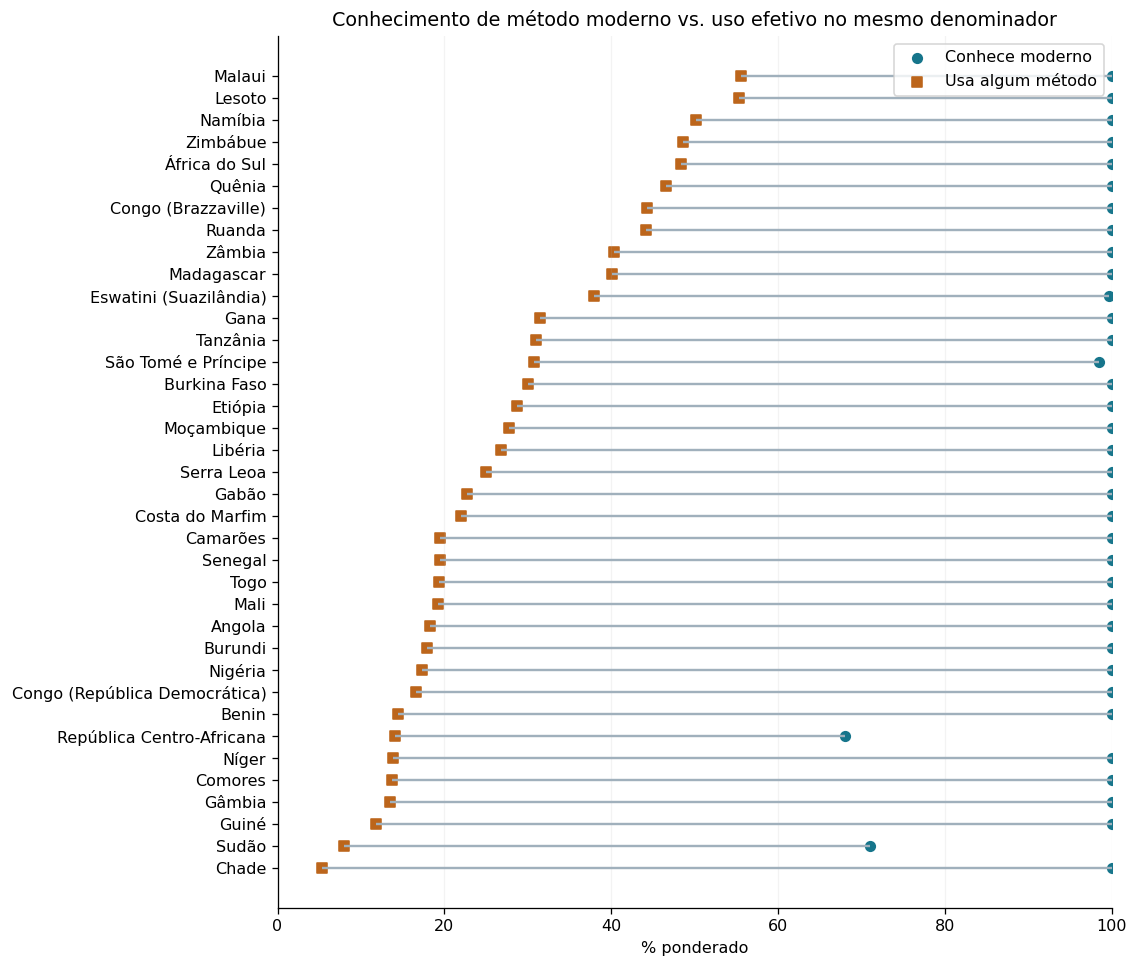

codigo,nome,mulheres_respostas_validas,percentual_conhece_moderno,percentual_uso_qualquer,criancas_avaliadas,doses_aplicadas_pct,sarampo_pct
AO,Angola,11999,100.00,18.26,6617.0,43.47,33.10
BJ,Benin,14868,100.00,15.36,7796.0,67.63,47.11
BF,Burkina Faso,16877,100.00,31.47,6718.0,79.35,63.05
BU,Burundi,16735,100.00,18.43,7625.0,87.62,69.15
CM,Camarões,12998,100.00,20.29,NaN,NaN,NaN
TD,Chade,8517,100.00,9.34,16897.0,46.93,47.43
KM,Comores,5127,100.00,14.23,3022.0,68.98,61.52
CG,Congo (Brazzaville),10509,100.00,45.12,8857.0,67.17,59.17
CD,Congo (República Democrática),22477,100.00,19.19,13414.0,42.17,36.95
CI,Costa do Marfim,13363,100.00,24.03,5918.0,62.92,46.00


nome,mulheres_respostas_validas,diferenca_pp,doses_aplicadas_pct,sarampo_pct
Angola,11999,81.74,43.47,33.10
Benin,15928,85.59,67.63,47.11
Burkina Faso,17659,69.94,79.35,63.05
Burundi,17269,82.11,87.62,69.15
Camarões,13527,80.48,NaN,NaN
Chade,17719,94.65,46.93,47.43
Comores,5329,86.34,68.98,61.52
Congo (Brazzaville),10819,55.66,67.17,59.17
Congo (República Democrática),27583,83.45,42.17,36.95
Costa do Marfim,14877,77.95,62.92,46.00


**Resultado:** **37 países** comparados; **33** atingem 100% na codificação 0–7 (que inclui o código `7` para sondagem fora do módulo padrão; a análise de sensibilidade 0–3 explicita o denominador restrito). Mesmo onde o conhecimento de métodos modernos supera 90% e a aplicação das 8 vacinas básicas (`Crianca_Vacina`) alcança mediana superior a 70%, o uso contraceptivo efetivo permanece significativamente menor, evidenciando barreiras socioeconômicas e de acesso além da informação.

In [17]:
sql_8 = """
WITH conhecimento AS (
  SELECT k.mulher_id,
         CASE WHEN MAX(k.nivel > 0) = 1 THEN 1 WHEN COUNT(*) = 7 THEN 0 END AS conhece_moderno
  FROM Conhecimento_Metodo k
  JOIN Metodo t ON t.id = k.metodo_id
  WHERE t.classe = 'Moderno'
  GROUP BY k.mulher_id
),
vacinacao_pais AS (
  SELECT l.pais_codigo AS codigo,
         COUNT(DISTINCT c.nascimento_id) AS criancas_avaliadas,
         ROUND(100.0*SUM(CASE WHEN cv.status_codigo IN (1,2,3) THEN 1 ELSE 0 END)/NULLIF(COUNT(cv.vacina_id),0),2) AS doses_aplicadas_pct,
         ROUND(100.0*SUM(CASE WHEN v.codigo='h9' AND cv.status_codigo IN (1,2,3) THEN 1 ELSE 0 END)/NULLIF(SUM(CASE WHEN v.codigo='h9' THEN 1 ELSE 0 END),0),2) AS sarampo_pct
  FROM Crianca c
  JOIN Nascimento n ON n.id = c.nascimento_id
  JOIN Mulher m ON m.id = n.mulher_id
  JOIN Domicilio d ON d.id = m.domicilio_id
  JOIN Levantamento l ON l.id = d.levantamento_id
  JOIN Crianca_Vacina cv ON cv.nascimento_id = c.nascimento_id
  JOIN Vacina_Remedio v ON v.id = cv.vacina_id
  GROUP BY l.pais_codigo
)
SELECT p.codigo, p.nome,
       COUNT(*) AS mulheres_respostas_validas,
       ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS percentual_conhece_moderno,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_qualquer,
       vp.criancas_avaliadas,
       vp.doses_aplicadas_pct,
       vp.sarampo_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN conhecimento k ON k.mulher_id = m.id
LEFT JOIN vacinacao_pais vp ON vp.codigo = p.codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND k.conhece_moderno IS NOT NULL
GROUP BY p.codigo, p.nome
ORDER BY p.nome
"""
display(Markdown("```sql\n" + sql_8.strip() + "\n```"))
r8 = consulta(sql_8, amostra=False)
pares(r8.set_index('nome').rename(columns={'percentual_conhece_moderno':'Conhece moderno', 'percentual_uso_qualquer':'Usa algum método'}), 'Conhece moderno', 'Usa algum método', 'Conhecimento de método moderno vs. uso efetivo no mesmo denominador', '% ponderado')

sql_sensibilidade_8 = sql_8.replace("WHERE t.classe = 'Moderno'", "WHERE t.classe = 'Moderno' AND k.nivel BETWEEN 0 AND 3")
r8_explicito = pd.read_sql_query(sql_sensibilidade_8, conn)
detalhes(r8_explicito, 'Sensibilidade Q8 · códigos explícitos 0–3 · denominador específico')
r8['diferenca_pp'] = r8.percentual_conhece_moderno - r8.percentual_uso_qualquer
detalhes(r8[['nome', 'mulheres_respostas_validas', 'diferenca_pp', 'doses_aplicadas_pct', 'sarampo_pct']], 'Diferenças conhecimento−uso e cobertura vacinal infantil')
display(Markdown(
    f"**Resultado:** **{len(r8)} países** comparados; **{int((r8.percentual_conhece_moderno == 100).sum())}** atingem 100% na codificação 0–7 (que inclui o código `7` para sondagem fora do módulo padrão; a análise de sensibilidade 0–3 explicita o denominador restrito). "
    f"Mesmo onde o conhecimento de métodos modernos supera 90% e a aplicação das 8 vacinas básicas (`Crianca_Vacina`) alcança mediana superior a 70%, o uso contraceptivo efetivo permanece significativamente menor, evidenciando barreiras socioeconômicas e de acesso além da informação."
))

## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Consulta 9 — Agregação ponderada de contracepção por estrato socioeconômico (`Entrevista ⋈ Mulher ⋈ Domicilio ⋈ Levantamento ⋈ Pais`)

Agrega o total de entrevistas e os pesos amostrais por país, área de residência, quintil de riqueza e nível de escolaridade. Esta consulta fornece os estratos multidimensionalmente cruzados para a padronização direta urbano-rural da Seção 6.5.

```sql
SELECT p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade,
       COUNT(*) AS n,
       SUM(e.peso) AS peso_total,
       SUM(e.peso * e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
  AND m.escolaridade BETWEEN 0 AND 3
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade
ORDER BY p.nome, d.residencia, d.riqueza, m.escolaridade
```

codigo,nome,residencia,riqueza,escolaridade,n,peso_total,peso_uso
AO,Angola,1,1,0,44,32.537380,0.379562
AO,Angola,1,1,1,37,34.691687,1.096992
AO,Angola,1,1,2,26,20.120082,2.879600
AO,Angola,1,2,0,284,210.090319,7.097133
AO,Angola,1,2,1,365,305.121579,15.571363
AO,Angola,1,2,2,281,233.272810,39.209519
AO,Angola,1,3,0,354,266.940714,17.497694
AO,Angola,1,3,1,813,774.803185,113.595157
AO,Angola,1,3,2,1523,1373.433466,252.920204
AO,Angola,1,3,3,23,13.033430,2.390045


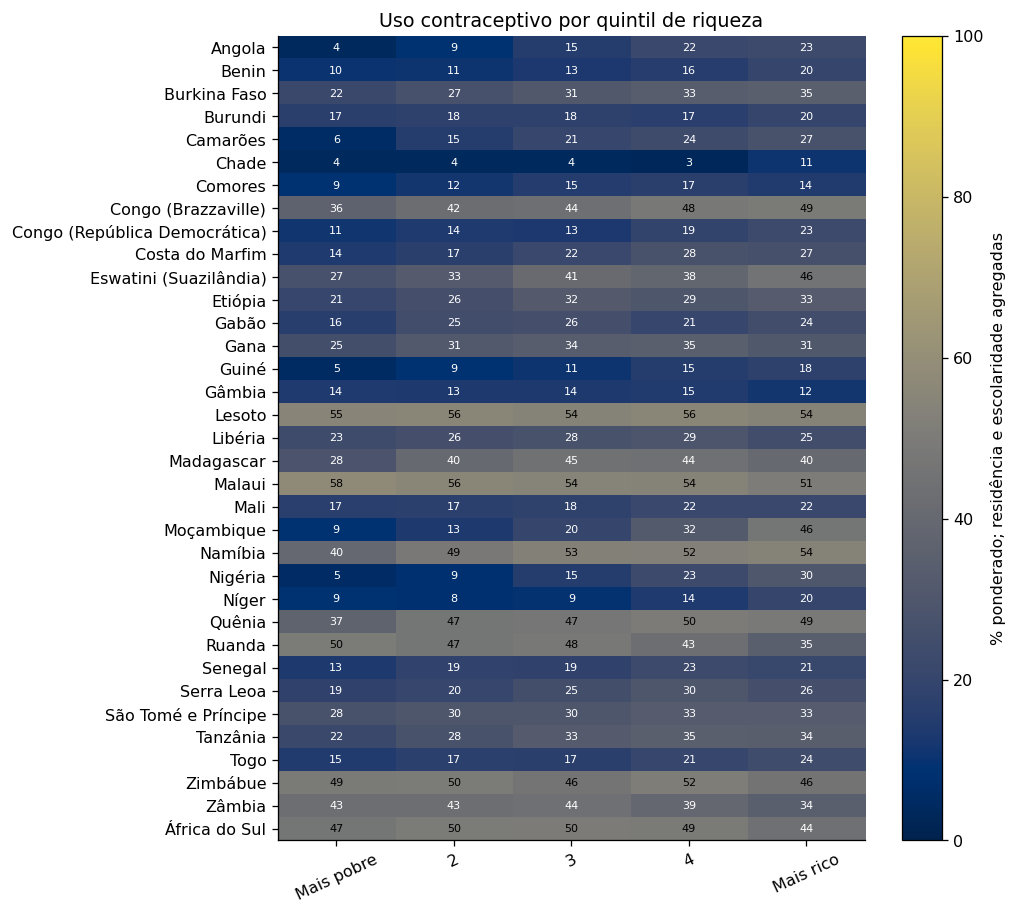

In [18]:
sql_9 = """
SELECT p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade,
       COUNT(*) AS n,
       SUM(e.peso) AS peso_total,
       SUM(e.peso * e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
  AND m.escolaridade BETWEEN 0 AND 3
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade
ORDER BY p.nome, d.residencia, d.riqueza, m.escolaridade
"""
display(Markdown("```sql\n" + sql_9.strip() + "\n```"))
r9 = consulta(sql_9, amostra=False)
por_riqueza = r9.groupby(['nome', 'riqueza'])[['peso_total', 'peso_uso']].sum()
por_riqueza['uso'] = 100 * por_riqueza.peso_uso / por_riqueza.peso_total
mapa(por_riqueza.uso.unstack().rename(columns={1:'Mais pobre', 5:'Mais rico'}), 'Uso contraceptivo por quintil de riqueza', '% ponderado; residência e escolaridade agregadas')

### 6.4.2 Consulta 10 — Agregação ponderada de pré-natal adequado (≥4 consultas) por residência e riqueza (`Entrevista ⋈ Mulher ⋈ Domicilio ⋈ Levantamento ⋈ Pais ⋈ Nascimento`)

Agrega os nascimentos mais recentes dos últimos 60 meses por país, residência e quintil de riqueza, calculando os pesos amostrais válidos e os pesos correspondentes à realização de quatro ou mais consultas de pré-natal (`consultas_prenatal_codigo BETWEEN 4 AND 90`).

```sql
SELECT p.codigo, p.nome, d.residencia, d.riqueza,
       COUNT(*) AS nascimentos_recentes,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS n_validos,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4 AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza
ORDER BY p.nome, d.residencia, d.riqueza
```

codigo,nome,residencia,riqueza,nascimentos_recentes,n_validos,peso_valido,peso_quatro_mais
AO,Angola,1,1,66,50,38.705283,14.212405
AO,Angola,1,2,558,425,338.977883,144.427086
AO,Angola,1,3,1537,1127,974.057613,618.625296
AO,Angola,1,4,1174,795,870.177007,702.901841
AO,Angola,1,5,873,595,710.826592,649.617429
AO,Angola,2,1,1946,1548,1229.179719,312.428171
AO,Angola,2,2,1245,993,967.351867,360.262453
AO,Angola,2,3,336,260,201.882627,116.874049
AO,Angola,2,4,60,46,36.156285,25.425303
AO,Angola,2,5,30,18,12.173921,11.714798


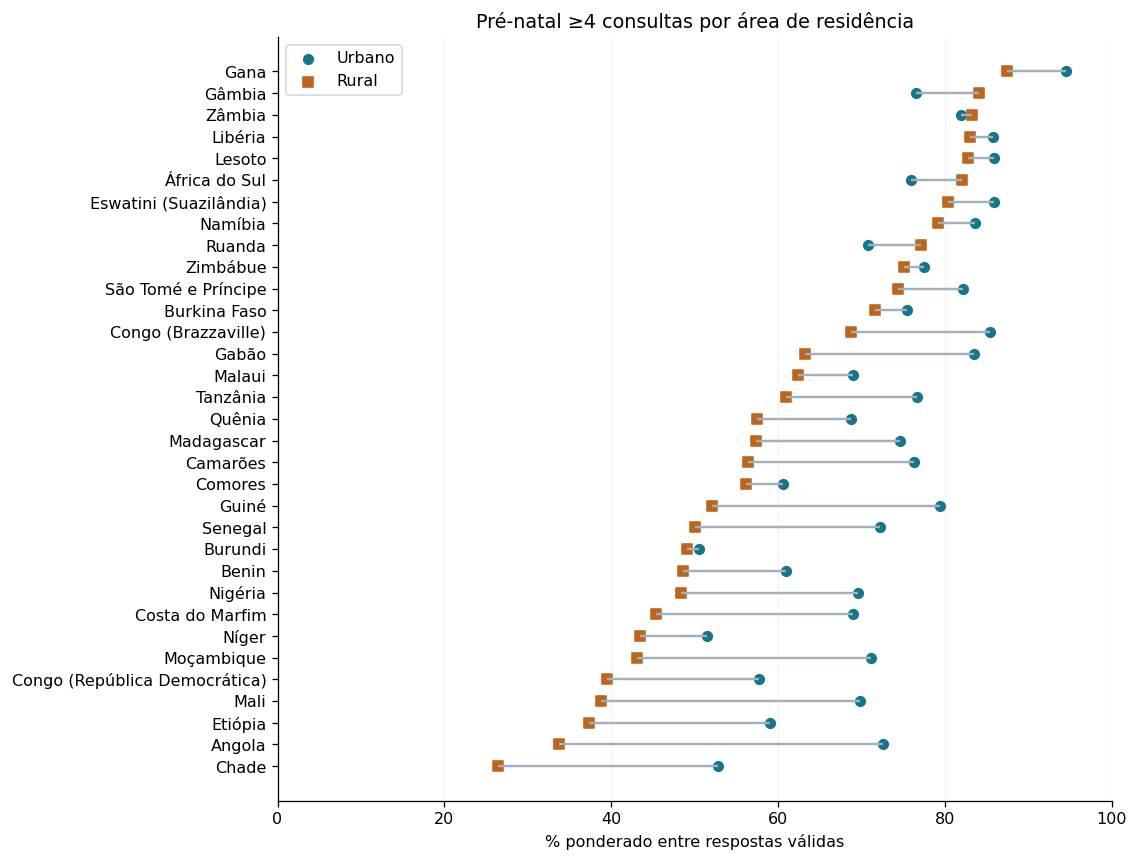

In [19]:
sql_10 = """
SELECT p.codigo, p.nome, d.residencia, d.riqueza,
       COUNT(*) AS nascimentos_recentes,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 ELSE 0 END) AS n_validos,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4 AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza
ORDER BY p.nome, d.residencia, d.riqueza
"""
display(Markdown("```sql\n" + sql_10.strip() + "\n```"))
r10 = consulta(sql_10, amostra=False)
por_area = r10.groupby(['nome', 'residencia'])[['peso_valido', 'peso_quatro_mais']].sum()
por_area['prenatal'] = 100 * por_area.peso_quatro_mais / por_area.peso_valido.replace(0, np.nan)
pares(por_area.prenatal.unstack().rename(columns={1:'Urbano', 2:'Rural'}), 'Urbano', 'Rural', 'Pré-natal ≥4 consultas por área de residência', '% ponderado entre respostas válidas')

## 6.5 Comparações padronizadas entre áreas urbanas e rurais

Para responder diretamente à questão central do projeto (*"Quanto das diferenças rurais e urbanas se relacionam à riqueza e à escolaridade?"*):
- **Contracepção (`comparar_residencias` e `verificar_sensibilidade`):** Calculamos a diferença bruta (Urbano $-$ Rural) no suporte comum e a diferença padronizada pela distribuição conjunta de riqueza e escolaridade (exigindo $\ge 30$ respostas por área/estrato, com análise de sensibilidade para limiares de 50 e 100 respostas).
- **Pré-natal (`comparar_prenatal`):** Avaliamos o gradiente ponderado de realização de $\ge 4$ consultas de pré-natal entre os quintis de riqueza em todos os países.

codigo,pais,estratos,bruta_pp,padronizada_pp,suporte_urbano_pct,suporte_rural_pct,inversao
ST,São Tomé e Príncipe,10,-8.59,-9.73,92.96,93.38,False
MD,Madagascar,15,-2.77,-6.96,98.91,95.87,False
ZM,Zâmbia,11,-7.62,-5.58,93.60,63.76,False
KE,Quênia,17,1.86,-4.93,99.16,98.49,True
LB,Libéria,13,1.55,-4.45,82.43,98.37,True
GH,Gana,16,-0.37,-4.05,97.29,99.05,False
ET,Etiópia,11,2.00,-3.90,94.09,73.05,True
AO,Angola,10,11.47,-3.43,79.43,94.56,True
RW,Ruanda,15,-8.57,-2.89,98.84,99.20,False
CI,Costa do Marfim,14,5.86,-2.65,84.91,98.98,True


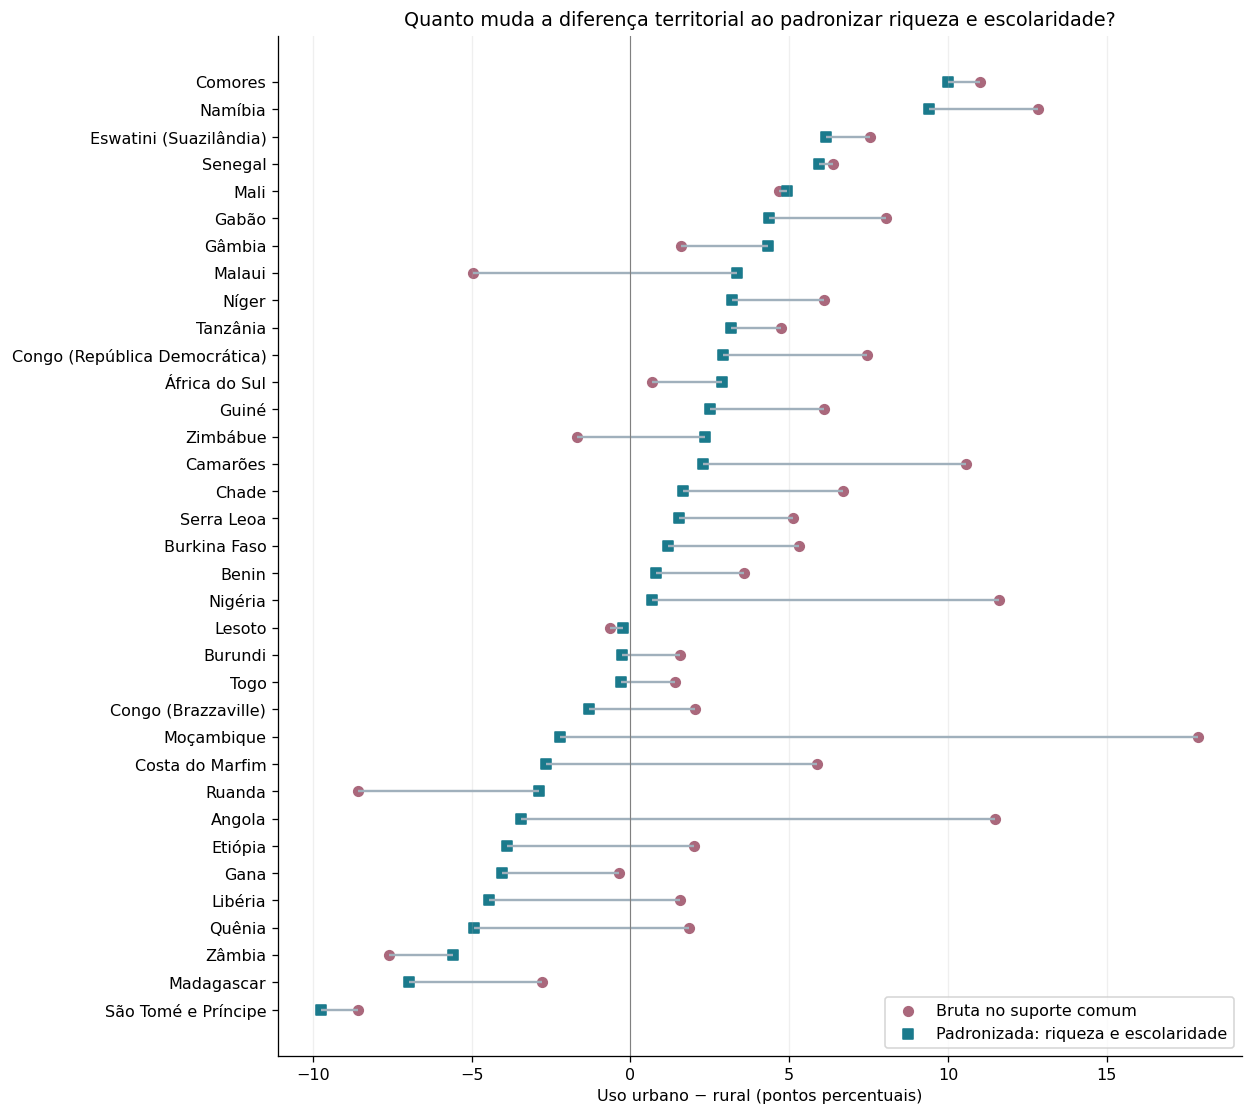

**Resultado:** 35 países com suporte comum; uso urbano maior após o ajuste em 20; 11 inversões de sinal. Maiores mudanças: Moçambique, Angola, Nigéria.

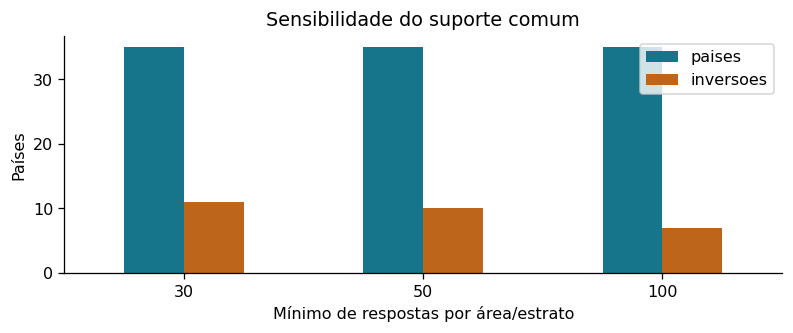

codigo,pais,minimo_por_area,estratos,bruta_pp,padronizada_pp,inversao
AO,Angola,30,10,11.47,-3.43,True
BF,Burkina Faso,30,12,5.31,1.17,False
BJ,Benin,30,15,3.57,0.80,False
BU,Burundi,30,11,1.57,-0.25,True
CD,Congo (República Democrática),30,13,7.45,2.91,False
CG,Congo (Brazzaville),30,7,2.04,-1.30,True
CI,Costa do Marfim,30,14,5.86,-2.65,True
CM,Camarões,30,11,10.56,2.28,False
ET,Etiópia,30,11,2.00,-3.90,True
GA,Gabão,30,7,8.06,4.38,False


**Sensibilidade:** inversão nos três limiares em Congo (Brazzaville), Costa do Marfim, Libéria, Malaui, Moçambique, Quênia, Togo. Os estratos incluídos mudam com o limiar.

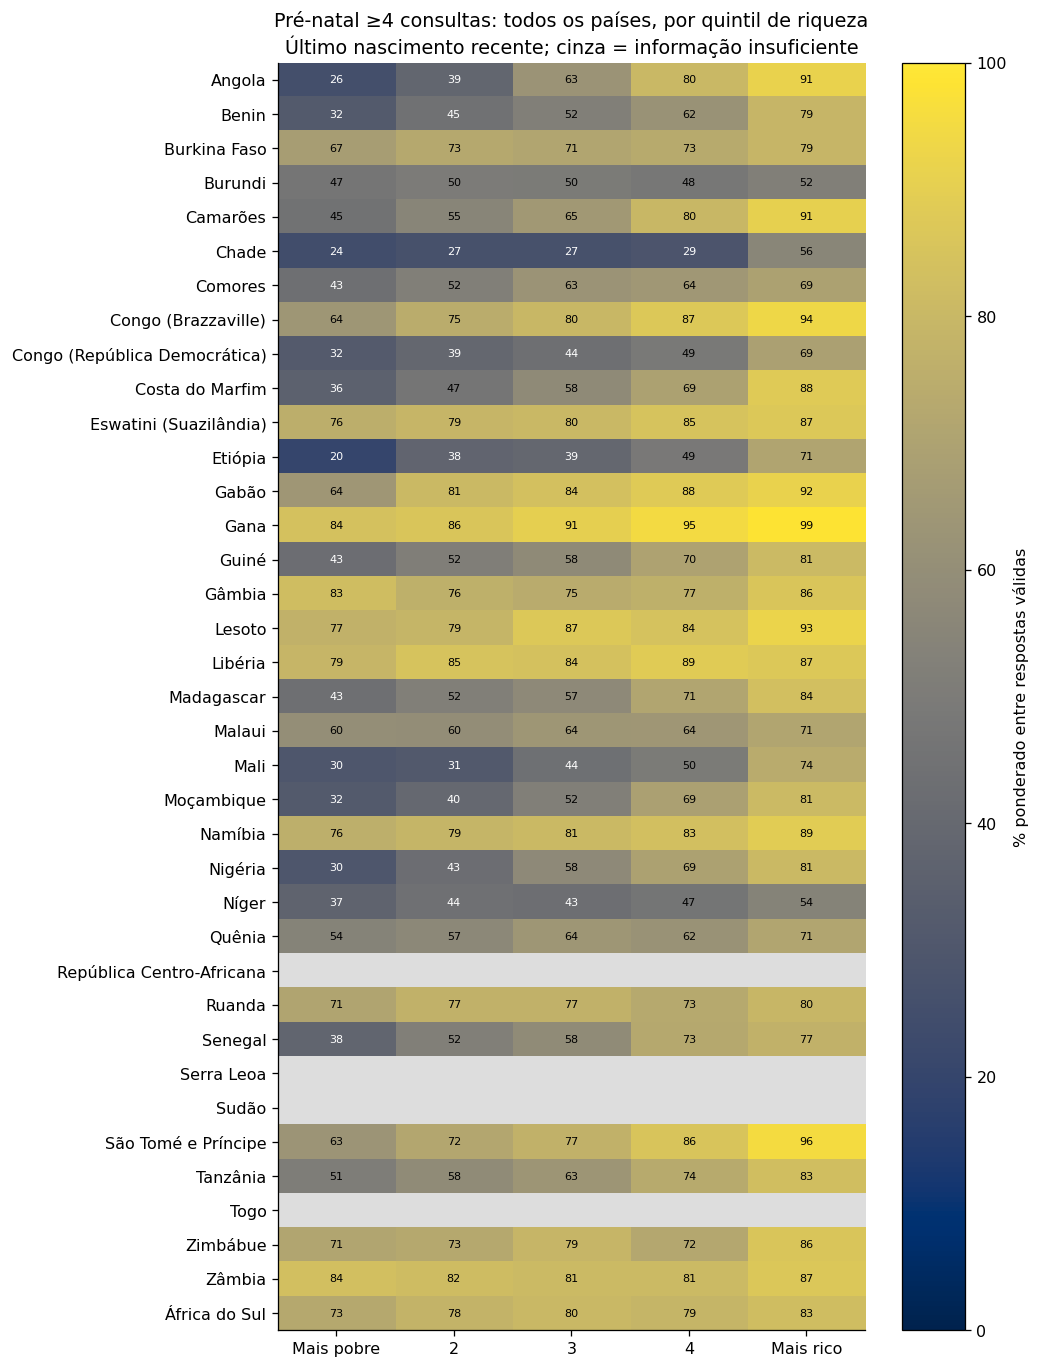

riqueza,nome,1,5,diferenca_pp
,Angola,25.76,91.47,65.71
,Benin,31.81,79.17,47.36
,Burkina Faso,67.28,79.17,11.88
,Burundi,47.07,52.18,5.11
,Camarões,45.29,90.94,45.64
,Chade,24.28,55.55,31.26
,Comores,43.42,69.46,26.04
,Congo (Brazzaville),64.05,93.71,29.66
,Congo (República Democrática),32.39,69.10,36.71
,Costa do Marfim,35.91,87.97,52.06


nome,n_validos,nascimentos_recentes,cobertura_pct
Angola,5857,7825,74.85
Benin,8750,8977,97.47
Burkina Faso,6384,9292,68.70
Burundi,8634,8639,99.94
Camarões,2324,3085,75.33
Chade,10928,11104,98.41
Comores,1730,2016,85.81
Congo (Brazzaville),6429,6463,99.47
Congo (República Democrática),12241,15064,81.26
Costa do Marfim,5657,7660,73.85


**Resultado:** pré-natal ≥4 maior no quintil mais rico em 33 de 33 países com respostas suficientes; diferença de 3.2 a 65.7 pontos percentuais.

Países sem suporte comum suficiente: CF, SD


In [20]:
from database_python.relatorio_notebook import comparar_residencias, verificar_sensibilidade, comparar_prenatal

ajustes = comparar_residencias(r9, cobertura)
sensibilidade = verificar_sensibilidade(r9)
prenatal = comparar_prenatal(r10, cobertura)

## 6.6 Otimização de Consultas

Avaliamos o impacto físico da criação do índice de cobertura `idx_entrevista_ano_uso` sobre `Entrevista(ano, usa_metodo, mulher_id, peso)` para acelerar a agregação filtrada por ano da entrevista e uso de método contraceptivo. Comparamos o plano de execução (`EXPLAIN QUERY PLAN`), a equivalência exata dos resultados e a mediana de sete execuções consecutivas.

```sql
SELECT p.nome,m.escolaridade,COUNT(*) AS n,SUM(e.peso) AS peso
    FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
    JOIN Domicilio d ON d.id=m.domicilio_id
    JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
    WHERE e.ano=? AND e.usa_metodo=1
    GROUP BY p.nome,m.escolaridade ORDER BY p.nome,m.escolaridade
```

```sql
CREATE INDEX idx_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso);
```

id,parent,notused,detail
16,0,65,SCAN p USING INDEX sqlite_autoindex_Pais_2
19,0,48,SEARCH l USING INDEX idx_lev_pais (pais_codigo=?)
25,0,62,SEARCH d USING INDEX idx_dom_levantamento (levantamento_id=?)
31,0,48,SEARCH m USING INDEX sqlite_autoindex_Mulher_2 (domicilio_id=?)
37,0,46,SEARCH e USING INDEX sqlite_autoindex_Entrevista_1 (mulher_id=?)
47,0,0,USE TEMP B-TREE FOR GROUP BY


id,parent,notused,detail
15,0,54,SEARCH e USING COVERING INDEX idx_entrevista_ano_uso (ano=? AND usa_metodo=?)
22,0,46,SEARCH m USING INDEX sqlite_autoindex_Mulher_1 (id=?)
28,0,46,SEARCH d USING INDEX sqlite_autoindex_Domicilio_1 (id=?)
33,0,35,SEARCH l USING INDEX sqlite_autoindex_Levantamento_1 (id=?)
38,0,35,SEARCH p USING INDEX sqlite_autoindex_Pais_1 (codigo=?)
43,0,0,USE TEMP B-TREE FOR GROUP BY


**Plano:** SCAN p USING INDEX sqlite_autoindex_Pais_2 → SEARCH e USING COVERING INDEX idx_entrevista_ano_uso (ano=? AND usa_metodo=?)

execucao,antes_ms,depois_ms
1,448.9936,50.5480
2,483.0685,49.9874
3,489.0952,50.1849
4,487.4588,49.1645
5,488.2288,50.2802
6,485.9363,50.3786
7,493.3095,50.3427


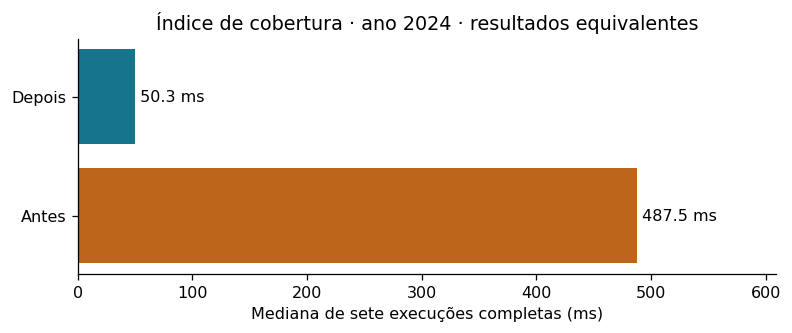

**Resultado:** 487.46 → 50.28 ms; redução de 89.7%. Criação do índice: 0.39 s. Resultados equivalentes; ganho específico deste filtro.

Banco derivado final com índice e estatísticas; resultados equivalentes confirmados.
Validação final concluída: 13 tabelas íntegras, 10 consultas validadas e otimização verificada.


In [21]:
from database_python.relatorio_notebook import medir_otimizacao

medir_otimizacao(conn)

assert set(cobertura.codigo) == {r[0] for r in conn.execute('SELECT codigo FROM Pais')}
for numero in range(1, 11):
    tabela = globals()[f'r{numero}']
    assert len(tabela) > 0, f'Consulta {numero} deve retornar dados.'
    coluna = 'pais_codigo' if numero <= 5 else 'codigo'
    assert tabela[coluna].nunique() > 1, f'Consulta {numero} deve abranger vários países.'
assert set(r3.pais_codigo) == set(cobertura.codigo) - {'SD'}, 'Sudão não possui residência disponível neste recorte.'
assert len(ajustes) > 1 and len(prenatal) > 1
assert set(panorama.codigo) == set(cobertura.codigo)
assert set(r8.codigo) == set(cobertura.codigo)
assert r9.codigo.nunique() == 35
conn.close()
assert sha256(origem) == hash_origem
print('Validação final concluída: 13 tabelas íntegras, 10 consultas validadas e otimização verificada.')

# 7. Autoavaliação dos membros

- **Henrique Lima Gusmão** - Sugestão de datasets; Solicitação de dados à agência americana; Plano de proposta da saúde da mulher africana; Importação dos 9GB de dados; Filtragem e normalização dos dados referentes às mulheres, domicílios, moradores, crianças e parceiros; Criação de repositório; Criação do Python/Flask para análise visual dos dados; Tradução dos códigos para os respectivos nomes das entidades; Seções Descrição e Inovação Social da primeira proposta; Descrição, Manipulação de dados, Consultas SQL, Otimização e Diagrama Relacional alinhado ao Diagrama ER.

- **Felipe Pires Franco** - 

- **Izabella Galdino Correia** - 

- **Alice Lina Oliveira da Silva** - 

# 8. Declaração de Uso de Inteligência Artificial

Nesta seção, declaramos como ferramentas de Inteligência Artificial (IA) foram utilizadas durante o desenvolvimento deste trabalho.

### Ferramentas e finalidades de uso

- **ChatGPT Sol 6.1 Alto, no Codex**: Para a criação do visualizador Python/Flask e automação da correlação dos códigos dos atributos ao inglês e tradução ao português; Correção pontual de erros nos códigos SQL.
- **Gemini 3.8 Flash / Claude Opus 4.6, no Antigravity**: Para a instalação de pacotes necessários para testar o notebook, alinhamento das tabelas do banco SQLite ao Diagrama ER.

### O que não foi feito com IA

Análise crítica/qualitativa do significado destes dados, primeiras versões dos códigos SQL e escolha dos territórios, evitando assim possíveis vieses analíticos. Os autores assumem inteira responsabilidade por este conteúdo, considerando que todos os códigos foram testados, conferidos e modificados a critério da pesquisa quando necessário.